# Optical measurements and fabric visibility

1. Build the optical and image metrics.
2. Compare and calibrate image metrics.
3. Explore the full dataset.
4. Fit and validate prediction models.

Run the analysis you need after checking its input paths. The cells use Google Drive paths under `/content/drive/MyDrive/Master`.

## 1. Build the optical and image metrics

### Combined optical–image report (55-sample MATLAB port)

The current configuration uses the nonwoven-plus-two-lace spectral workbooks and saves `nonwoven + 2 lace_report.xlsx`. The next cell shows the alternate paths for the full dataset.

Processing 22 fabric samples...
Sample "blue + 2 black on white"  -->  matched image: "Blue + 2 black Cabinet.JPG"
Sample "blue + 2 green on white"  -->  matched image: "Blue + 2 green Cabinet.JPG"
Sample "blue + 2 grey on white"  -->  matched image: "Blue + 2 grey Cabinet.JPG"
Sample "blue + 2 red on white"  -->  matched image: "Blue + 2 red Cabinet.JPG"
Sample "blue + 2 white on white"  -->  matched image: "Blue + 2 white Cabinet.JPG"
Sample "brown + 2 black on white"  -->  matched image: "Brown + 2 black Cabinet.JPG"
Sample "brown + 2 green on white"  -->  matched image: "Brown + 2 green Cabinet.JPG"
Sample "brown + 2 grey on white"  -->  matched image: "Brown + 2 grey Cabinet.JPG"
Sample "brown + 2 white on white"  -->  matched image: "Brown + 2 white Cabinet.JPG"
Sample "red + 2 black on white"  -->  matched image: "Red + 2 black Cabinet.JPG"
Sample "red + 2 green on white"  -->  matched image: "Red + 2 green Cabinet.JPG"
Sample "red + 2 grey on white"  -->  matched image: "Red + 

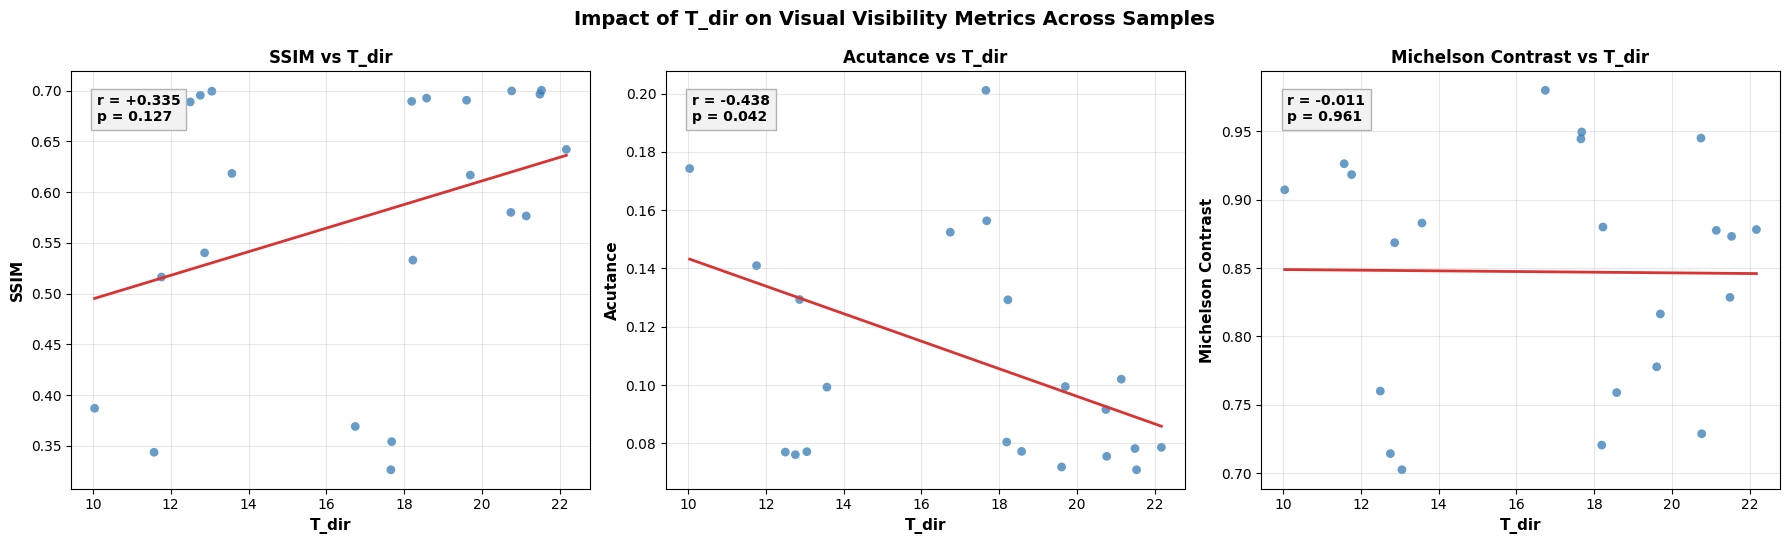

Saved plot to /content/drive/MyDrive/Master/All data report/nonwoven + 2 lace plot_Diffuseness_Ratio.png


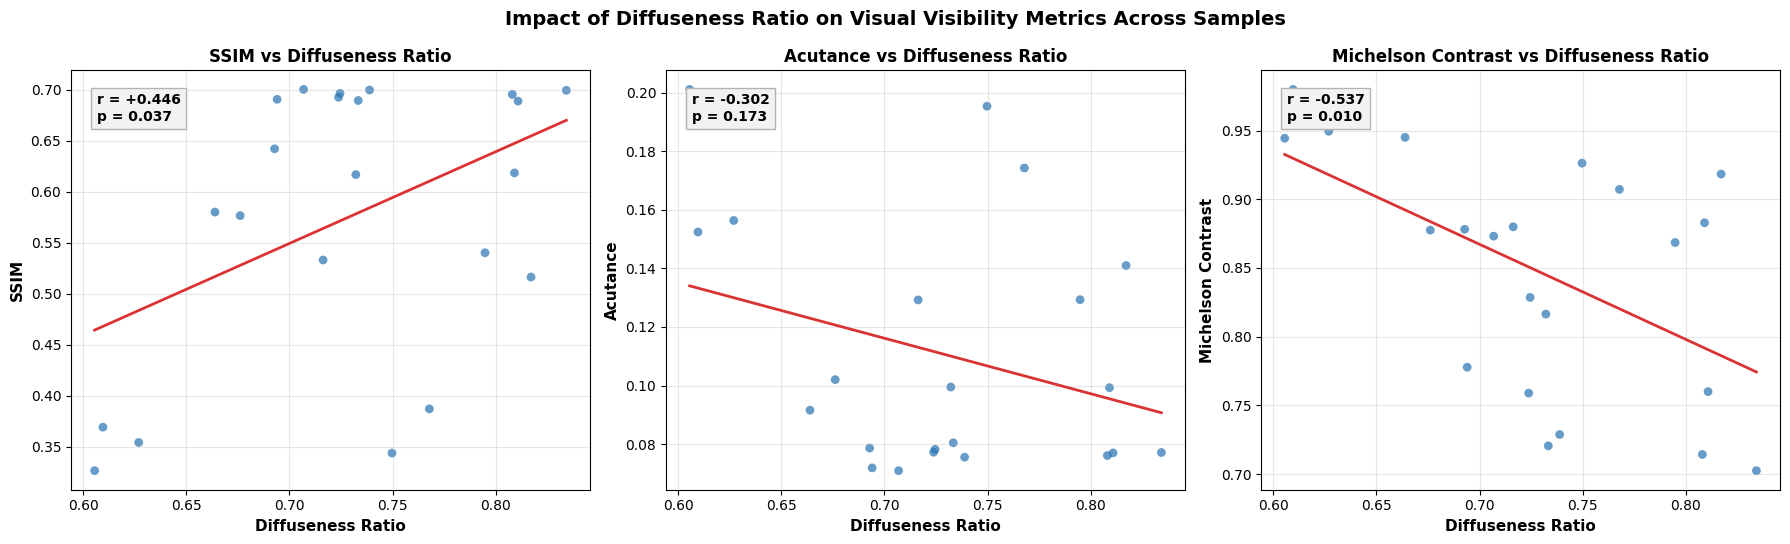

Saved plot to /content/drive/MyDrive/Master/All data report/nonwoven + 2 lace plot_Opacity_R_b_R_w_.png


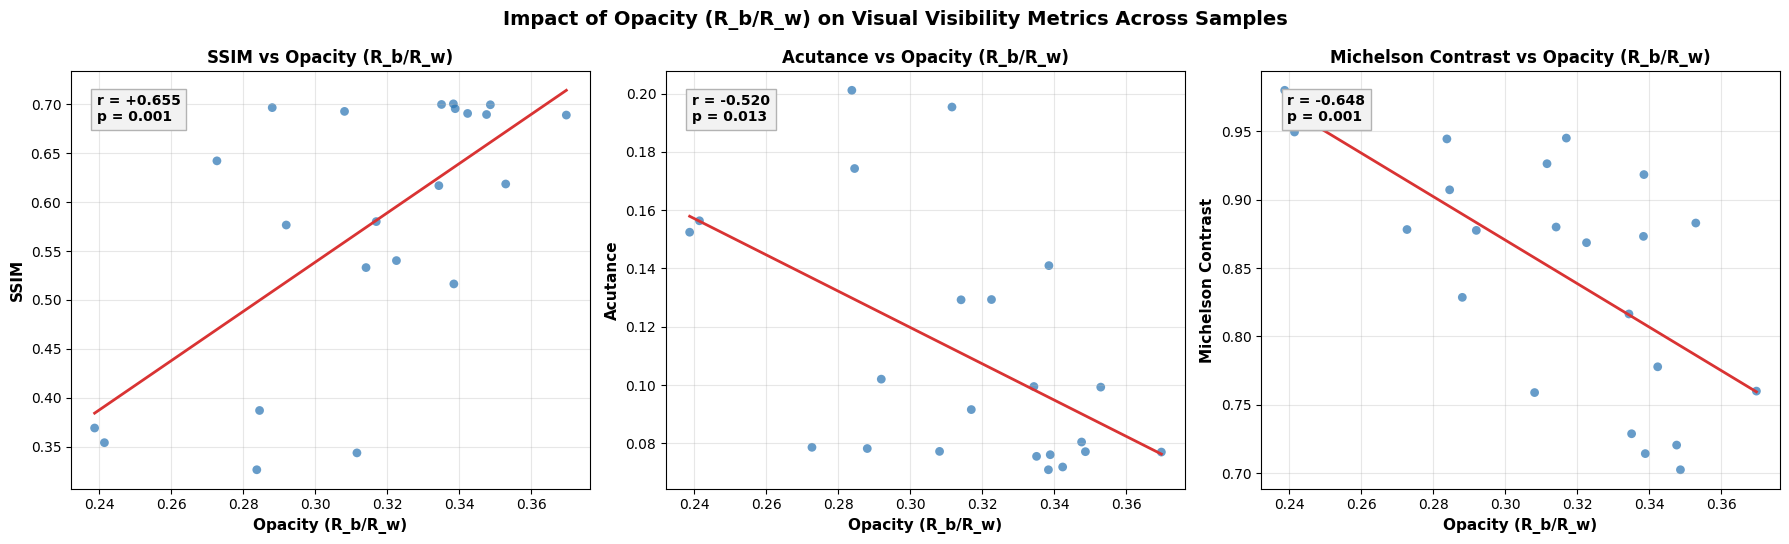

In [ ]:
"""
Python port of code_55samples.m — 1:1 translation, same structure and
formulas.
"""

import os
import re
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func
from scipy.stats import pearsonr


TOTAL_FILE   = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Transmittance on white.xlsx"
DIFFUSE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Tranmsittance on black.xlsx"
R_WHITE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on white.xlsx"
R_BLACK_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on black.xlsx"
PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"
D65_FILE      = "/content/drive/MyDrive/Master/D65.xlsx"

REF_FILENAME = "/content/drive/MyDrive/Master/All images/No fabric cabinet.JPG"
IMAGE_DIR    = "/content/drive/MyDrive/Master/All images"

OUTPUT_DIR = "/content/drive/MyDrive/Master/All data report"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------------
# 1. IMPORT SPECTRAL DATA FROM EXCEL
# ---------------------------------------------------------------
T_tot_tbl  = pd.read_excel(TOTAL_FILE,   header=0, index_col=0).dropna(how='all')
T_diff_tbl = pd.read_excel(DIFFUSE_FILE, header=0, index_col=0).dropna(how='all')
R_w_tbl    = pd.read_excel(R_WHITE_FILE, header=0, index_col=0).dropna(how='all')
R_b_tbl    = pd.read_excel(R_BLACK_FILE, header=0, index_col=0).dropna(how='all')

file_counts = {
    TOTAL_FILE: len(T_tot_tbl),
    DIFFUSE_FILE: len(T_diff_tbl),
    R_WHITE_FILE: len(R_w_tbl),
    R_BLACK_FILE: len(R_b_tbl),
}
if len(set(file_counts.values())) > 1:
    lines = "\n".join(f"  {n} rows -- {f}" for f, n in file_counts.items())
    print("T_tot rows: ", T_tot_tbl.index.tolist())
    print("T_diff rows:", T_diff_tbl.index.tolist())
    print("R_w rows:   ", R_w_tbl.index.tolist())
    print("R_b rows:   ", R_b_tbl.index.tolist())
    raise ValueError(
        f"Row count mismatch across spectral files -- they must all have "
        f"the same number of samples:\n{lines}\n"
        f"Check the printed row labels above to see exactly which sample "
        f"is missing or extra."
    )

num_samples = len(T_tot_tbl)

T_tot  = T_tot_tbl.iloc[:num_samples, :].to_numpy()
T_diff = T_diff_tbl.iloc[:num_samples, :].to_numpy()
R_w    = R_w_tbl.iloc[:num_samples, :].to_numpy()
R_b    = R_b_tbl.iloc[:num_samples, :].to_numpy()

df_photopic = pd.read_excel(PHOTOPIC_FILE, header=0)
df_d65      = pd.read_excel(D65_FILE, header=0)
V   = df_photopic.iloc[:31, 1].to_numpy()
D65 = df_d65.iloc[:31, 1].to_numpy()

weight_vec = D65 * V
sum_weight = np.sum(weight_vec)

weighted_T_tot  = (T_tot  @ weight_vec) / sum_weight
weighted_T_diff = (T_diff @ weight_vec) / sum_weight
weighted_T_dir  = weighted_T_tot - weighted_T_diff
diffuseness     = weighted_T_diff / weighted_T_tot

weighted_R_b = (R_b @ weight_vec) / sum_weight
weighted_R_w = (R_w @ weight_vec) / sum_weight
opacity      = weighted_R_b / weighted_R_w

# ---------------------------------------------------------------
# 2. DEFINE REFERENCE IMAGE AND CROPPING ROI
# ---------------------------------------------------------------
ref_path = os.path.join(IMAGE_DIR, REF_FILENAME)
if not os.path.isfile(ref_path):
    raise FileNotFoundError(f'Reference image "{REF_FILENAME}" not found in {IMAGE_DIR}.')

ref_img = cv2.cvtColor(cv2.imread(ref_path), cv2.COLOR_BGR2GRAY).astype(np.float64)

img_h, img_w = ref_img.shape
roi_x = round(img_w * 0.25)
roi_y = round(img_h * 0.52)
roi_w = round(img_w * 0.50)
roi_h = round(img_h * 0.40)


def crop_roi(img):
    return img[roi_y:roi_y + roi_h, roi_x:roi_x + roi_w]


ref_roi_raw  = crop_roi(ref_img)
ref_roi_norm = ref_roi_raw / 255.0
ref_roi_norm = ref_roi_norm / np.mean(ref_roi_norm)

# ---------------------------------------------------------------
# 3. DYNAMIC FILENAME MATCHING AND METRIC COMPUTATION
# ---------------------------------------------------------------
ssim_vals = np.full(num_samples, np.nan)
acutance  = np.full(num_samples, np.nan)
contrast  = np.full(num_samples, np.nan)

all_jpg_paths = sorted(set(
    glob.glob(os.path.join(IMAGE_DIR, "*.jpg")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.JPG")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.Jpg"))
))
all_jpg_names = [os.path.basename(p) for p in all_jpg_paths]

sample_names = T_tot_tbl.index.tolist()

print(f"Processing {num_samples} fabric samples...")

for k in range(num_samples):
    raw_label = str(sample_names[k]).strip()

    clean_label = re.sub(r'\s+on white$', '', raw_label, flags=re.IGNORECASE)
    clean_label = re.sub(r'\s+nonwoven$', '', clean_label, flags=re.IGNORECASE)
    norm_label = re.sub(r'\s+', '', clean_label).lower()

    exact_match = None
    fuzzy_match = None

    for fname in all_jpg_names:
        if fname.lower() == REF_FILENAME.lower():
            continue

        name_only = os.path.splitext(fname)[0]
        norm_fname = re.sub(r'\s+', '', name_only).lower()
        norm_fname = re.sub(r'cabinet$', '', norm_fname)

        if norm_label == norm_fname:
            exact_match = fname
            break

        if fuzzy_match is None and (norm_label in norm_fname or norm_fname in norm_label):
            fuzzy_match = fname

    if exact_match is not None:
        matched_filename = exact_match
    elif fuzzy_match is not None:
        matched_filename = fuzzy_match
        print(f'  WARNING: no exact match for "{raw_label}" -- used fuzzy/substring '
              f'match "{fuzzy_match}" instead. Verify this is correct.')
    else:
        matched_filename = None

    if matched_filename is not None:
        print(f'Sample "{raw_label}"  -->  matched image: "{matched_filename}"')

        img_path = os.path.join(IMAGE_DIR, matched_filename)
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2GRAY).astype(np.float64)
        img_roi_raw = crop_roi(img)

        img_roi_scaled = img_roi_raw / 255.0
        img_roi_norm = img_roi_scaled / np.mean(img_roi_scaled)


        dyn_range = ref_roi_norm.max() - ref_roi_norm.min()
        ssim_vals[k] = ssim_func(img_roi_norm, ref_roi_norm, data_range=dyn_range,
                                  gaussian_weights=True, sigma=1.5,
                                  use_sample_covariance=False)


        gx = cv2.Sobel(img_roi_scaled, cv2.CV_64F, 1, 0, ksize=3)
        gy = cv2.Sobel(img_roi_scaled, cv2.CV_64F, 0, 1, ksize=3)
        gmag = np.sqrt(gx**2 + gy**2)
        acutance[k] = np.mean(gmag)

        contrast[k] = (img_roi_scaled.max() - img_roi_scaled.min()) / \
                      (img_roi_scaled.max() + img_roi_scaled.min())
    else:
        print(f'Sample "{raw_label}"  -->  NO MATCHING IMAGE FOUND (set to NaN)')

# ---------------------------------------------------------------
# 4. CORRELATION ANALYSIS & FORMATTED PRINT
# ---------------------------------------------------------------
X = np.column_stack([weighted_T_dir, diffuseness, opacity])
Y = np.column_stack([ssim_vals, acutance, contrast])

predictor_names = ['T_dir', 'Diffuseness Ratio', 'Opacity (R_b/R_w)']
response_names  = ['SSIM', 'Acutance', 'Michelson Contrast']

r_threshold = 0.70
p_threshold = 0.05

R_matrix = np.full((3, 3), np.nan)
P_values = np.full((3, 3), np.nan)

for i in range(3):
    for j in range(3):
        mask = ~np.isnan(X[:, i]) & ~np.isnan(Y[:, j])
        if mask.sum() > 1:
            r, p = pearsonr(X[mask, i], Y[mask, j])
            R_matrix[i, j] = r
            P_values[i, j] = p

print("\n" + "=" * 99)
print(f"         CORRELATION MATRIX: FABRIC OPTICAL PROPERTIES vs. IMAGE QUALITY METRICS ({num_samples} SAMPLES)      ")
print("=" * 99)

header = f"{'Optical Predictor (X)':<28} | " + " | ".join(f"{name:<22}" for name in response_names)
print(header)
print("-" * 99)

for i in range(3):
    row = f"{predictor_names[i]:<28} | "
    cells = []
    for j in range(3):
        r_val, p_val = R_matrix[i, j], P_values[i, j]
        sig_flag = '*' if p_val < p_threshold else ' '
        if abs(r_val) >= r_threshold:
            cell_str = f"{r_val:+6.3f}{sig_flag} (p={p_val:.3f}) [STRONG]"
        else:
            cell_str = f"{r_val:+6.3f}{sig_flag} (p={p_val:.3f})"
        cells.append(f"{cell_str:<22}")
    print(row + " | ".join(cells))

print("=" * 99)
print(f"Notes: [STRONG] indicates strong correlation (|r| >= {r_threshold:.2f}). "
      f"* denotes p < {p_threshold:.2f}.\n")

# ---------------------------------------------------------------
# 4b. SAVE REPORT (per-sample values + correlation matrix + p-values)
# ---------------------------------------------------------------
correlation_table = pd.DataFrame(R_matrix, index=predictor_names, columns=response_names)
pvalue_table       = pd.DataFrame(P_values, index=predictor_names, columns=response_names)

report_path = os.path.join(OUTPUT_DIR, "nonwoven + 2 lace_report.xlsx")
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    pd.DataFrame({
        'Sample': sample_names,
        'weighted_T_tot': weighted_T_tot,
        'weighted_T_diff': weighted_T_diff,
        'weighted_T_dir': weighted_T_dir,
        'diffuseness': diffuseness,
        'opacity': opacity,
        'SSIM': ssim_vals,
        'Acutance': acutance,
        'Michelson_Contrast': contrast,
    }).to_excel(writer, sheet_name="Per-Sample Values", index=False)
    correlation_table.to_excel(writer, sheet_name="Correlation (R)")
    pvalue_table.to_excel(writer, sheet_name="p-values")

print(f"Saved report to {report_path}")

# ---------------------------------------------------------------
# 5. VISUALIZATION: OPTICAL PROPERTIES vs. IMAGE METRICS
# ---------------------------------------------------------------
scatter_color = (0.15, 0.45, 0.70)
line_color    = (0.85, 0.20, 0.20)

for i in range(3):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    fig.suptitle(f"Impact of {predictor_names[i]} on Visual Visibility Metrics Across Samples",
                 fontsize=14, fontweight='bold')

    x_val = X[:, i]

    for j in range(3):
        ax = axes[j]
        y_val = Y[:, j]

        valid = ~np.isnan(x_val) & ~np.isnan(y_val)
        x_clean, y_clean = x_val[valid], y_val[valid]

        ax.scatter(x_clean, y_clean, s=40, color=scatter_color, alpha=0.7, edgecolor='none')

        if len(x_clean) > 1:
            p_fit = np.polyfit(x_clean, y_clean, 1)
            x_fit = np.linspace(x_clean.min(), x_clean.max(), 100)
            y_fit = np.polyval(p_fit, x_fit)
            ax.plot(x_fit, y_fit, color=line_color, linewidth=2)

        r_val, p_val = R_matrix[i, j], P_values[i, j]
        stats_str = f"r = {r_val:+0.3f}\np = {p_val:0.3f}"
        xl, yl = ax.get_xlim(), ax.get_ylim()
        ax.text(xl[0] + 0.05 * (xl[1] - xl[0]), yl[1] - 0.12 * (yl[1] - yl[0]),
                stats_str, fontsize=10, fontweight='bold',
                bbox=dict(facecolor=(0.95, 0.95, 0.95), edgecolor=(0.7, 0.7, 0.7)))

        ax.set_xlabel(predictor_names[i], fontsize=11, fontweight='bold')
        ax.set_ylabel(response_names[j], fontsize=11, fontweight='bold')
        ax.set_title(f"{response_names[j]} vs {predictor_names[i]}", fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)

    plt.tight_layout()

    safe_name = re.sub(r'[^\w\-]+', '_', predictor_names[i])
    plot_path = os.path.join(OUTPUT_DIR, f"nonwoven + 2 lace plot_{safe_name}.png")
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    print(f"Saved plot to {plot_path}")

    plt.show()

### Alternate paths for the full dataset

To use these inputs, copy the settings into the configuration at the top of the preceding report cell, set the report filename to `all_report.xlsx` if you want to use it in sections 3–4, and run the report cell.

In [ ]:
TOTAL_FILE   = "/content/drive/MyDrive/Master/Data 9th September/All Transmittance on white background.xlsx"
DIFFUSE_FILE = "/content/drive/MyDrive/Master/Data 9th September/All Transmittance on black background.xlsx"
R_WHITE_FILE = "/content/drive/MyDrive/Master/Data 9th September/All Reflection on white background.xlsx"
R_BLACK_FILE = "/content/drive/MyDrive/Master/Data 9th September/All reflection on black background.xlsx"
PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"
D65_FILE      = "/content/drive/MyDrive/Master/D65.xlsx"

REF_FILENAME = "/content/drive/MyDrive/Master/All images/No fabric cabinet.JPG"
IMAGE_DIR    = "/content/drive/MyDrive/Master/All images"

OUTPUT_DIR = "/content/drive/MyDrive/Master/All data report"
os.makedirs(OUTPUT_DIR, exist_ok=True)

### Two-lace correlation report (earlier MATLAB port)

This version weights the spectra with D65 from `exe_4.mat` and pairs sorted image filenames with sorted sample names. Review the printed alignment table before using the correlations.

In [ ]:
"""
Python replication of code2mardasi.m — exact structural match, with
auto-discovered images and name-sorted spectrophotometric data.

Section 1: optical parameters from spectrophotometric data
    weighted_T_tot, weighted_T_diff, weighted_T_dir, diffuseness
    weighted_R_b, weighted_R_w, opacity

Section 2: ROI-based image quality metrics
    SSIM, Acutance (mean Sobel gradient magnitude), Michelson contrast

Section 3: cross-correlation between optical parameters and image metrics
    R matrix + p-values, matching MATLAB's corr(X, Y)

ALIGNMENT STRATEGY (this is the part that changed from the previous
version): images are no longer listed by hand -- they're discovered from
IMG_FOLDER and sorted alphabetically by filename. Each Excel sheet
(T_tot/T_diff/R_w/R_b) is independently sorted alphabetically by its
sample-name index. As long as both sides are sorted the same way (A-Z by
name), row k of the sorted Excel data and image k of the sorted image
list describe the same fabric -- this is safer than relying on whatever
order rows/files happened to be in originally. The two sorted lists are
printed side-by-side before anything else runs so you can visually
confirm they actually match before trusting the results.

No /100 normalization anywhere -- matches the MATLAB script exactly. If
your Excel files are on a 0-100 percent scale, values here will be 100x
the equivalent 0-1 fraction used elsewhere in this project; confirm which
scale your actual files use before comparing against other scripts.
"""

import os
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func
from scipy.stats import pearsonr
from scipy.io import loadmat

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
TOTAL_FILE   = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Transmittance on white.xlsx"
DIFFUSE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Tranmsittance on black.xlsx"
R_WHITE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on white.xlsx"
R_BLACK_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on black.xlsx"

PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"
MAT_FILE = "/content/drive/MyDrive/Master/exe_4.mat"

IMG_FOLDER = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)"
REFERENCE_IMG_NAME = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG"   # excluded from auto-discovery
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

OUTPUT_DIR = IMG_FOLDER

# ---------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------
def find_fabric_images(folder, reference_filename):
    """
    Scan `folder` for image files, sorted alphabetically (case-insensitive)
    by filename. Skips the reference image and skips any subfolders.
    """
    candidates = []
    for ext in IMAGE_EXTENSIONS:
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext}")))
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext.upper()}")))
    candidates = list(set(candidates))

    ref_path = os.path.join(folder, reference_filename)
    fabric_paths = [
        p for p in candidates
        if os.path.isfile(p)                                   # skip subfolders
        and os.path.abspath(p) != os.path.abspath(ref_path)     # skip reference image
    ]
    fabric_paths.sort(key=lambda p: os.path.basename(p).lower())
    return fabric_paths


def sample_title(path):
    """'.../White cabinet.JPG' -> 'White cabinet' -- used only for display."""
    return os.path.splitext(os.path.basename(path))[0]


def load_sorted(path):
    """Load an Excel sheet and sort its rows alphabetically (case-
    insensitive) by the sample-name index, so row order no longer depends
    on how the sheet happened to be entered."""
    df = pd.read_excel(path, header=0, index_col=0)
    df = df.loc[sorted(df.index, key=lambda name: str(name).strip().lower())]
    return df


def imread_gray(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)


# ---------------------------------------------------------------
# SECTION 0: DISCOVER IMAGES, LOAD + SORT EXCEL DATA, CHECK ALIGNMENT
# ---------------------------------------------------------------
IMG_FILES = find_fabric_images(IMG_FOLDER, REFERENCE_IMG_NAME)
IMG_TITLES = [sample_title(p) for p in IMG_FILES]
N_SAMPLES = len(IMG_FILES)

df_t_tot   = load_sorted(TOTAL_FILE)
df_t_diff  = load_sorted(DIFFUSE_FILE)
df_r_white = load_sorted(R_WHITE_FILE)
df_r_black = load_sorted(R_BLACK_FILE)

sample_names = df_t_tot.index.tolist()

print(f"Found {N_SAMPLES} fabric image(s) in {IMG_FOLDER}")
print("\nAlignment check -- these two columns should describe the same fabrics, in the same order:")
print(f"{'Image (sorted by filename)':35s} | {'Excel sample name (sorted)':35s}")
print("-" * 73)
for i in range(max(N_SAMPLES, len(sample_names))):
    img_label = IMG_TITLES[i] if i < N_SAMPLES else "<no image>"
    excel_label = sample_names[i] if i < len(sample_names) else "<no row>"
    flag = "" if i < N_SAMPLES and i < len(sample_names) else "  <-- MISMATCH IN COUNT"
    print(f"{img_label:35s} | {str(excel_label):35s}{flag}")

if N_SAMPLES != len(sample_names):
    raise ValueError(
        f"Number of images ({N_SAMPLES}) does not match number of Excel "
        f"samples ({len(sample_names)}). Check the printed table above, "
        f"fix the mismatch, and re-run."
    )

print("\nIf any row above doesn't actually describe the same fabric, STOP and fix "
      "the filename or the Excel sample name before trusting the results below.\n")

T_tot  = df_t_tot.to_numpy()
T_diff = df_t_diff.to_numpy()
R_w    = df_r_white.to_numpy()
R_b    = df_r_black.to_numpy()

# ---------------------------------------------------------------
# SECTION 1: PHOTOPIC V(lambda) AND D65
# ---------------------------------------------------------------
# V(lambda) -- CIE_sle_photopic (1).xlsx is the LONG-FORM file (not
# already 31 rows), so it needs the same downsampling used in your other
# scripts: data rows 41-341 (0-indexed 40:341), then every 10th row.
df_photopic = pd.read_excel(PHOTOPIC_FILE, sheet_name=0, header=None)
df_photopic = df_photopic.iloc[40:341, [0, 1]]
df_photopic.columns = ["wavelength", "V"]
V = df_photopic.iloc[::10]["V"].to_numpy()   # shape (31,)

# D65 -- from the .mat file, matching your other scripts
mat_data = loadmat(MAT_FILE)
D65 = mat_data['D65'].reshape(-1)            # shape (31,)

print("T_tot shape:", T_tot.shape)
print("T_diff shape:", T_diff.shape)
print("R_w shape:", R_w.shape)
print("R_b shape:", R_b.shape)
print("V shape:", V.shape, " D65 shape:", D65.shape)

# ---------------------------------------------------------------
# SECTION 1b: WEIGHTED (LUMINOUS) OPTICAL PARAMETERS
#
#   weighted_X = sum( X(lambda) * V(lambda) * D65(lambda) ) / sum( V(lambda) * D65(lambda) )
# ---------------------------------------------------------------
weights = V * D65  # shape (31,)
weights_sum = np.sum(weights)


def weighted_mean(X):
    """X: shape (n_samples, 31) -> shape (n_samples,)"""
    return np.sum(X * weights, axis=1) / weights_sum


weighted_T_tot  = weighted_mean(T_tot)
weighted_T_diff = weighted_mean(T_diff)
weighted_T_dir  = weighted_T_tot - weighted_T_diff
diffuseness     = weighted_T_diff / weighted_T_tot

weighted_R_b = weighted_mean(R_b)
weighted_R_w = weighted_mean(R_w)
opacity      = weighted_R_b / weighted_R_w

# ---------------------------------------------------------------
# SECTION 2a: LOAD IMAGES, DEFINE ROI
# ---------------------------------------------------------------
ref_img = imread_gray(os.path.join(IMG_FOLDER, REFERENCE_IMG_NAME))
img_h, img_w = ref_img.shape

# roi_rect = [xmin, ymin, width, height], matching MATLAB proportions
roi_x = round(img_w * 0.25)
roi_y = round(img_h * 0.55)
roi_w = round(img_w * 0.50)
roi_h = round(img_h * 0.40)


def crop_roi(img):
    """Equivalent to MATLAB's imcrop(img, roi_rect)."""
    return img[roi_y:roi_y + roi_h, roi_x:roi_x + roi_w]


ref_roi = crop_roi(ref_img)

# ---------------------------------------------------------------
# SECTION 2b: ROI PREVIEW (visual QC, matches the MATLAB figure)
# ---------------------------------------------------------------
all_img_files = [os.path.join(IMG_FOLDER, REFERENCE_IMG_NAME)] + IMG_FILES
all_titles = ["Reference (No Fabric)"] + IMG_TITLES

n_total = len(all_img_files)
n_cols = 4
n_rows = int(np.ceil(n_total / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
fig.suptitle("Cropped Region of Interest (ROI) Overlay across All Samples",
             fontsize=14, fontweight='bold')

axes_flat = np.array(axes).reshape(-1)
for ax, path, title in zip(axes_flat, all_img_files, all_titles):
    raw_img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(raw_img)
    rect = plt.Rectangle((roi_x, roi_y), roi_w, roi_h,
                          edgecolor='red', facecolor='none', linewidth=2, linestyle='--')
    ax.add_patch(rect)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

for ax in axes_flat[n_total:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roi_preview.png"), dpi=150, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------------
# SECTION 2c: IMAGE QUALITY METRICS PER SAMPLE
# ---------------------------------------------------------------
ssim_vals = np.zeros(N_SAMPLES)
acutance  = np.zeros(N_SAMPLES)
contrast  = np.zeros(N_SAMPLES)

for k in range(N_SAMPLES):
    img = imread_gray(IMG_FILES[k])
    img_roi = crop_roi(img)

    # Metric 1: SSIM -- MATLAB's ssim() defaults to an 11x11 Gaussian
    # window (sigma=1.5); gaussian_weights=True replicates that default
    # instead of skimage's own default uniform window.
    ssim_vals[k] = ssim_func(img_roi, ref_roi, data_range=255,
                              gaussian_weights=True, sigma=1.5,
                              use_sample_covariance=False)

    # Metric 2: Edge Acutance -- mean Sobel gradient magnitude,
    # matching MATLAB's imgradient() default (Sobel operator)
    gx = cv2.Sobel(img_roi, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_roi, cv2.CV_64F, 0, 1, ksize=3)
    gmag = np.sqrt(gx**2 + gy**2)
    acutance[k] = np.mean(gmag)

    # Metric 3: Michelson Contrast
    contrast[k] = (img_roi.max() - img_roi.min()) / (img_roi.max() + img_roi.min())

# ---------------------------------------------------------------
# SECTION 3: CROSS-CORRELATION ANALYSIS
# ---------------------------------------------------------------
X = np.column_stack([weighted_T_dir, diffuseness, opacity])
Y = np.column_stack([ssim_vals, acutance, contrast])

predictor_names = ['T_dir', 'Diffuseness_Ratio', 'Opacity']
response_names  = ['SSIM', 'Acutance', 'Michelson_Contrast']

R_matrix = np.zeros((X.shape[1], Y.shape[1]))
P_values = np.zeros((X.shape[1], Y.shape[1]))

for i in range(X.shape[1]):
    for j in range(Y.shape[1]):
        r, p = pearsonr(X[:, i], Y[:, j])
        R_matrix[i, j] = r
        P_values[i, j] = p

correlation_table = pd.DataFrame(R_matrix, index=predictor_names, columns=response_names)
pvalue_table       = pd.DataFrame(P_values, index=predictor_names, columns=response_names)

print("\n" + "=" * 50)
print("   RESULTS: OPTICAL PROPERTIES vs IMAGE QUALITY INDICES")
print("=" * 50)
print("\nCorrelation coefficients (R):")
print(correlation_table)
print("\np-values:")
print(pvalue_table)

# Optional: save everything to Excel for the thesis writeup
with pd.ExcelWriter(os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/optical_vs_image_correlation.xlsx"), engine="openpyxl") as writer:
    pd.DataFrame({
        'Sample': sample_names,
        'Image_file': [os.path.basename(p) for p in IMG_FILES],
        'weighted_T_tot': weighted_T_tot,
        'weighted_T_diff': weighted_T_diff,
        'weighted_T_dir': weighted_T_dir,
        'diffuseness': diffuseness,
        'opacity': opacity,
        'SSIM': ssim_vals,
        'Acutance': acutance,
        'Michelson_Contrast': contrast,
    }).to_excel(writer, sheet_name="Per-Sample Values", index=False)
    correlation_table.to_excel(writer, sheet_name="Correlation (R)")
    pvalue_table.to_excel(writer, sheet_name="p-values")

print(f"\nSaved full results to {os.path.join(OUTPUT_DIR, '/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/optical_vs_image_correlation.xlsx')}")

### Plot the nine optical–image pairs

This cell expects `optical_vs_image_correlation(2 lace).xlsx`. If you use the report from the preceding cell, set `REPORT_FILE` to its output, `optical_vs_image_correlation.xlsx`.

In [ ]:
"""
Plot each optical parameter (T_dir, diffuseness, opacity) against each
image quality parameter (SSIM, Acutance, Michelson_Contrast) as its own
separate scatter plot -- 9 plots total, one per pair.

Reads from the per-sample report already produced by the main pipeline
script (optical_vs_image_correlation.xlsx, sheet "Per-Sample Values"),
so this doesn't recompute anything -- just visualizes what's already
there.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/optical_vs_image_correlation(2 lace).xlsx"
SHEET_NAME = "Per-Sample Values"

OUTPUT_DIR = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)"

OPTICAL_PARAMS = ['weighted_T_dir', 'diffuseness', 'opacity']
IMAGE_PARAMS   = ['SSIM', 'Acutance', 'Michelson_Contrast']

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)

print(f"Loaded {len(df)} samples")
print(df[['Sample'] + OPTICAL_PARAMS + IMAGE_PARAMS])

# ---------------------------------------------------------------
# PLOT EACH OPTICAL PARAMETER AGAINST EACH IMAGE PARAMETER, SEPARATELY
# ---------------------------------------------------------------
for opt_param in OPTICAL_PARAMS:
    for img_param in IMAGE_PARAMS:
        x = df[opt_param].to_numpy()
        y = df[img_param].to_numpy()
        r, p = pearsonr(x, y)

        fig, ax = plt.subplots(figsize=(7, 6))
        ax.scatter(x, y, s=60, color='steelblue', edgecolor='black', zorder=3)

        for i, sample in enumerate(df['Sample']):
            ax.annotate(str(sample), (x[i], y[i]),
                        textcoords="offset points", xytext=(6, 4), fontsize=8)

        ax.set_xlabel(opt_param)
        ax.set_ylabel(img_param)
        ax.set_title(f"{opt_param} vs {img_param}\nPearson r = {r:.3f}  (p = {p:.3g}, n = {len(x)})",
                     fontsize=11, fontweight='bold')
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        out_path = os.path.join(OUTPUT_DIR, f"{opt_param}_vs_{img_param}.png")
        plt.savefig(out_path, dpi=150, bbox_inches='tight')
        plt.show()

        print(f"Saved {out_path}  (r = {r:.3f}, p = {p:.3g})")

## 2. Compare and calibrate image metrics

### Compare three photo sets

Compare SSIM, edge acutance, and Michelson contrast across the nonwoven-plus-one-lace, nonwoven-plus-two-lace, and lace combination photo sets.

[Nonwoven + 1 lace] found 22 fabric image(s) in /content/drive/MyDrive/Master/Images 2th September((nonwoven + 1 layer lace)
  Blue + black Cabinet       SSIM=0.3621  Acutance=50.29  Contrast=0.9342
  Blue + green Cabinet       SSIM=0.5496  Acutance=20.21  Contrast=0.8862
  Blue + grey Cabinet        SSIM=0.5143  Acutance=28.15  Contrast=0.9130
  Blue + red Cabinet         SSIM=0.5584  Acutance=22.87  Contrast=0.9227
  Blue + white Cabinet       SSIM=0.5642  Acutance=19.27  Contrast=0.9163
  Brown + black Cabinet      SSIM=0.4268  Acutance=42.04  Contrast=0.9789
  Brown + green Cabinet      SSIM=0.5876  Acutance=18.81  Contrast=0.8745
  Brown + grey Cabinet       SSIM=0.5764  Acutance=22.80  Contrast=0.9310
  Brown + white Cabinet      SSIM=0.5881  Acutance=18.81  Contrast=0.8150
  Red + black Cabinet        SSIM=0.3593  Acutance=49.82  Contrast=0.8667
  Red + green Cabinet        SSIM=0.5492  Acutance=19.49  Contrast=0.7607
  Red + grey Cabinet         SSIM=0.4695  Acutance=32.10  Con

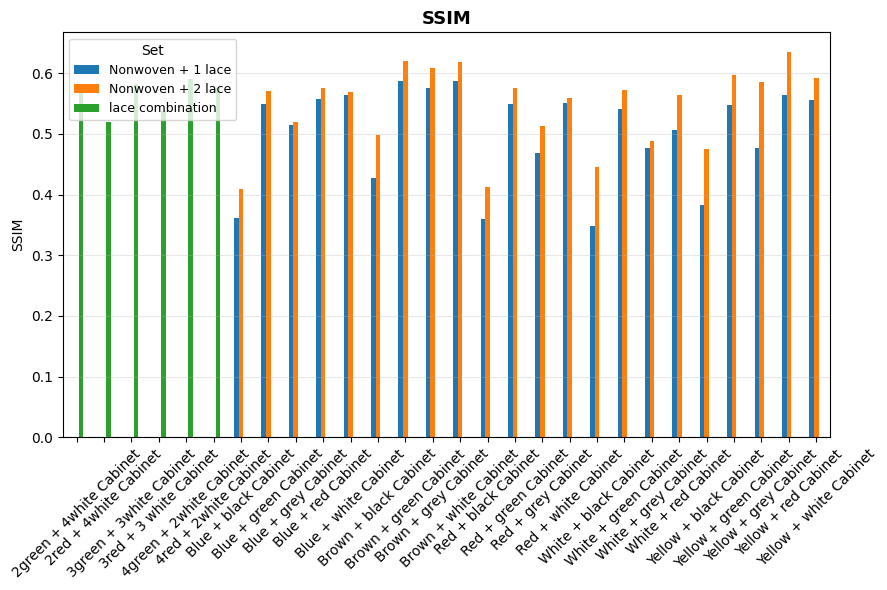

Saved SSIM comparison plot to /content/drive/MyDrive/Master/image_metrics_SSIM.png


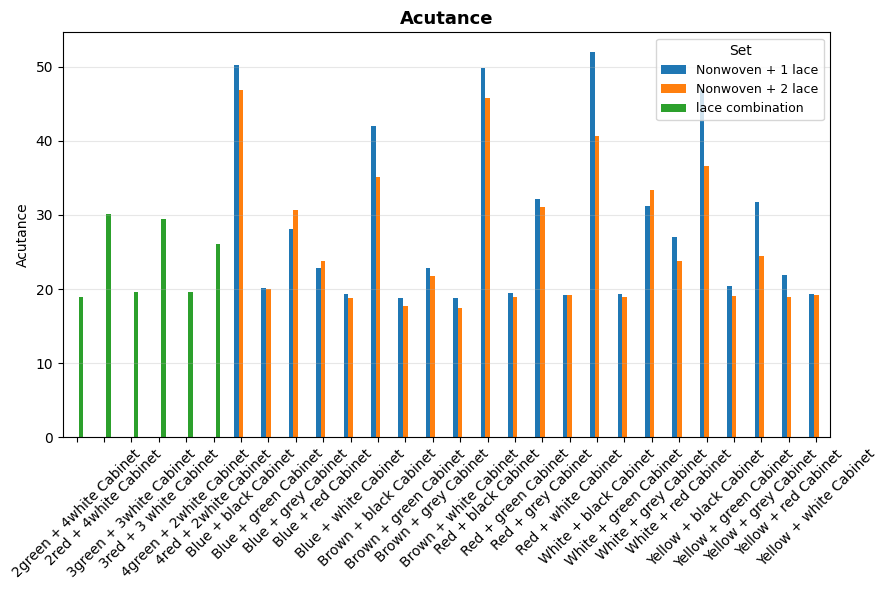

Saved Acutance comparison plot to /content/drive/MyDrive/Master/image_metrics_Acutance.png


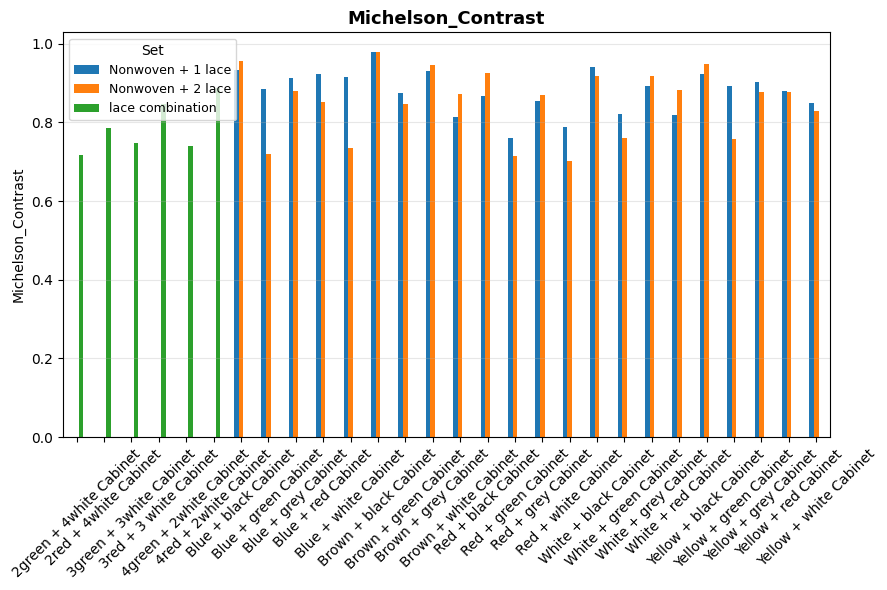

Saved Michelson_Contrast comparison plot to /content/drive/MyDrive/Master/image_metrics_Contrast.png


In [ ]:
 """
Compute SSIM, Edge Acutance, and Michelson Contrast for 3 sets of images,
and compare the sets against each other.

Two of the sets use identical filenames (e.g. both have "White cabinet.JPG"),
but the images themselves differ -- they were captured in different
sessions/folders. Filenames alone can't tell the sets apart, so each set
is defined by its own FOLDER, and every result is tagged with a `Set`
label. That label -- not the filename -- is what keeps the two
identically-named sets distinct throughout the analysis and the output
table/plots.

You do NOT need to list every image filename by hand: each set's fabric
images are discovered automatically by scanning its folder. Only the
reference (no-fabric) filename needs to be named explicitly, since it has
to be excluded from the "fabric images" list and used separately as the
comparison baseline.
"""

import os
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
# Each set = its own folder + its own reference filename. Fabric images are
# auto-discovered from the folder (everything except the reference).

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

SETS = [
    {
        "set_name": "Nonwoven + 1 lace",
        "folder": "/content/drive/MyDrive/Master/Images 2th September((nonwoven + 1 layer lace)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
    {
        "set_name": "Nonwoven + 2 lace",   # <- edit to your actual second session name
        "folder": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
    {
        "set_name": "lace combination",      # <- edit to your actual third session name
        "folder": "/content/drive/MyDrive/Master/Images 6th September(combination of lace fabrics)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
]

# ROI proportions -- same convention as before (fraction of image width/height)
ROI_FRAC = dict(x=0.25, y=0.55, w=0.50, h=0.40)

OUTPUT_FILE = "/content/drive/MyDrive/Master/image_metrics_by_set.xlsx"
PLOT_FILE   = "/content/drive/MyDrive/Master/image_metrics_by_set.png"

# ---------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------
def find_fabric_images(folder, reference_filename):
    """
    Scan `folder` for image files (case-insensitive extensions), excluding
    the reference image and anything with 'color checker' in the name.
    No fixed count assumed -- works whether a set has 3 fabrics or 12.
    """
    candidates = []
    for ext in IMAGE_EXTENSIONS:
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext}")))
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext.upper()}")))
    candidates = sorted(set(candidates))

    ref_path = os.path.join(folder, reference_filename)
    fabric_paths = [
        p for p in candidates
        if os.path.abspath(p) != os.path.abspath(ref_path)
        and 'color checker' not in os.path.basename(p).lower()
    ]
    return fabric_paths


def imread_gray(path):
    """Returns None instead of raising, so the caller can skip bad files."""
    img = cv2.imread(path)
    if img is None:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)


def compute_roi(img_shape, frac=ROI_FRAC):
    h, w = img_shape
    x = round(w * frac["x"])
    y = round(h * frac["y"])
    rw = round(w * frac["w"])
    rh = round(h * frac["h"])
    return x, y, rw, rh


def crop(img, roi):
    x, y, rw, rh = roi
    return img[y:y + rh, x:x + rw]


def sample_title(path):
    """'.../White cabinet.JPG' -> 'White cabinet' -- used only for display."""
    return os.path.splitext(os.path.basename(path))[0]


# ---------------------------------------------------------------
# COMPUTE METRICS FOR EACH SET
# ---------------------------------------------------------------
rows = []
skipped_all = []

for s in SETS:
    ref_path = os.path.join(s["folder"], s["reference"])
    ref_img = imread_gray(ref_path)
    if ref_img is None:
        raise FileNotFoundError(f"Could not read reference image: {ref_path}")

    roi = compute_roi(ref_img.shape)
    ref_roi = crop(ref_img, roi)

    fabric_paths = find_fabric_images(s["folder"], s["reference"])
    print(f"[{s['set_name']}] found {len(fabric_paths)} fabric image(s) in {s['folder']}")

    for img_path in fabric_paths:
        img = imread_gray(img_path)
        if img is None:
            skipped_all.append(img_path)
            continue

        img_roi = crop(img, roi)

        # Metric 1: SSIM
        ssim_val = ssim_func(img_roi, ref_roi, data_range=255,
                              gaussian_weights=True, sigma=1.5,
                              use_sample_covariance=False)

        # Metric 2: Edge Acutance -- mean Sobel gradient magnitude
        gx = cv2.Sobel(img_roi, cv2.CV_64F, 1, 0, ksize=3)
        gy = cv2.Sobel(img_roi, cv2.CV_64F, 0, 1, ksize=3)
        gmag = np.sqrt(gx**2 + gy**2)
        acutance_val = np.mean(gmag)

        # Metric 3: Michelson Contrast
        contrast_val = (img_roi.max() - img_roi.min()) / (img_roi.max() + img_roi.min())

        rows.append({
            "Set": s["set_name"],
            "Sample": sample_title(img_path),
            "SSIM": ssim_val,
            "Acutance": acutance_val,
            "Michelson_Contrast": contrast_val,
        })

        print(f"  {sample_title(img_path):25s}  "
              f"SSIM={ssim_val:.4f}  Acutance={acutance_val:.2f}  Contrast={contrast_val:.4f}")

results_df = pd.DataFrame(rows)

print(f"\nProcessed {len(rows)} image(s) total across {len(SETS)} set(s).")
if skipped_all:
    print(f"Skipped {len(skipped_all)} unreadable file(s): "
          f"{', '.join(os.path.basename(p) for p in skipped_all)}")

# ---------------------------------------------------------------
# SAVE RESULTS
# ---------------------------------------------------------------
metrics = ["SSIM", "Acutance", "Michelson_Contrast"]
set_names = [s["set_name"] for s in SETS]

PLOT_FILES = {
    "SSIM": "/content/drive/MyDrive/Master/image_metrics_SSIM.png",
    "Acutance": "/content/drive/MyDrive/Master/image_metrics_Acutance.png",
    "Michelson_Contrast": "/content/drive/MyDrive/Master/image_metrics_Contrast.png",
}

for metric in metrics:
    pivot = results_df.pivot(index="Sample", columns="Set", values=metric)
    pivot = pivot.reindex(columns=set_names)  # keep consistent set order/colors

    fig, ax = plt.subplots(figsize=(9, 6))
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title="Set", fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig(PLOT_FILES[metric], dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved {metric} comparison plot to {PLOT_FILES[metric]}")

### Calibrate metrics against controlled distortions

Apply blur, contrast compression, noise, and combined distortions to the no-fabric reference. Save the metric response curves and the calibration workbook.

=== Blur sweep ===
Blur_sigma=0         SSIM=1.0000  Acutance=0.05  Contrast=1.0000
Blur_sigma=0.5       SSIM=0.9959  Acutance=0.04  Contrast=1.0000
Blur_sigma=1         SSIM=0.9714  Acutance=0.03  Contrast=0.9980
Blur_sigma=1.5       SSIM=0.9553  Acutance=0.02  Contrast=0.9949
Blur_sigma=2         SSIM=0.9447  Acutance=0.02  Contrast=0.9929
Blur_sigma=3         SSIM=0.9297  Acutance=0.02  Contrast=0.9905
Blur_sigma=4         SSIM=0.9178  Acutance=0.02  Contrast=0.9883
Blur_sigma=5         SSIM=0.9074  Acutance=0.01  Contrast=0.9866
Blur_sigma=6         SSIM=0.8983  Acutance=0.01  Contrast=0.9857
Blur_sigma=8         SSIM=0.8827  Acutance=0.01  Contrast=0.9836
Blur_sigma=10        SSIM=0.8695  Acutance=0.01  Contrast=0.9820
Blur_sigma=13        SSIM=0.8535  Acutance=0.01  Contrast=0.9801
Blur_sigma=16        SSIM=0.8413  Acutance=0.01  Contrast=0.9765
Blur_sigma=20        SSIM=0.8291  Acutance=0.01  Contrast=0.9695
Blur_sigma=25        SSIM=0.8181  Acutance=0.01  Contrast=0.9612

=== B

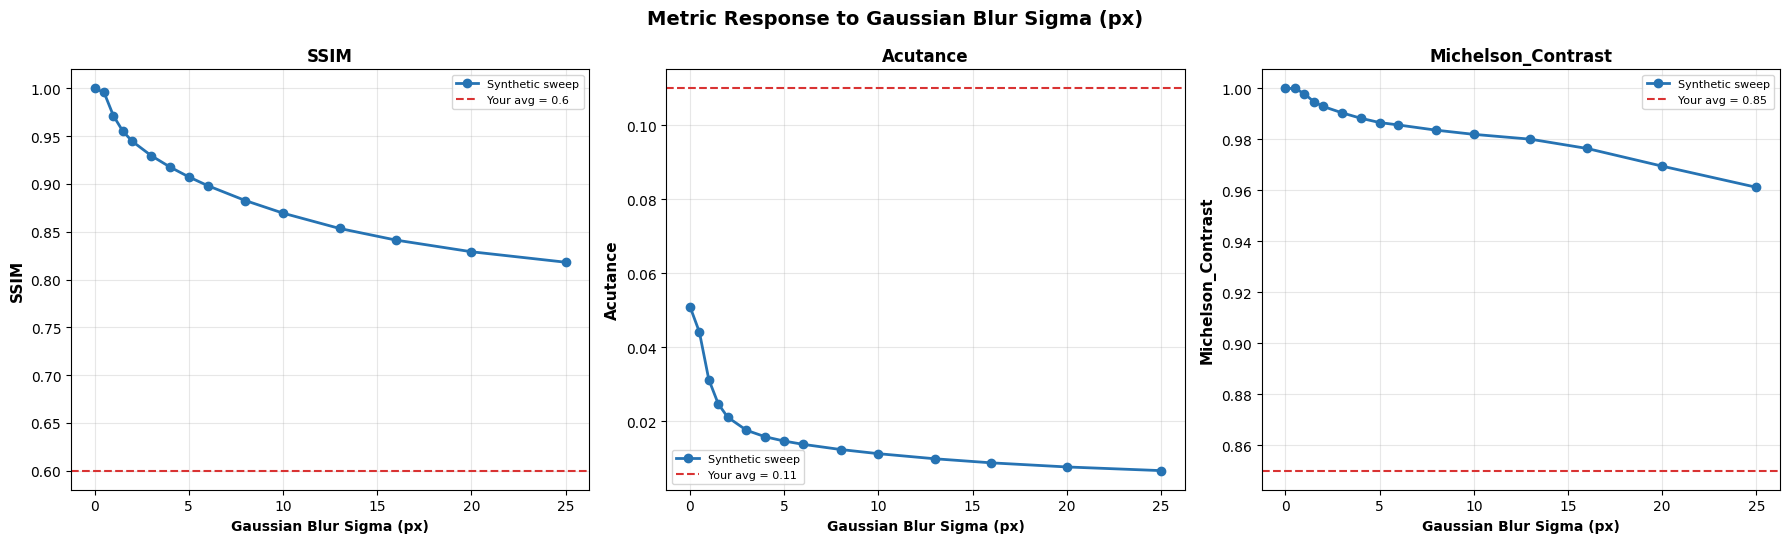

Saved plot to /content/drive/MyDrive/Master/Test parameters/calibration_compression.png


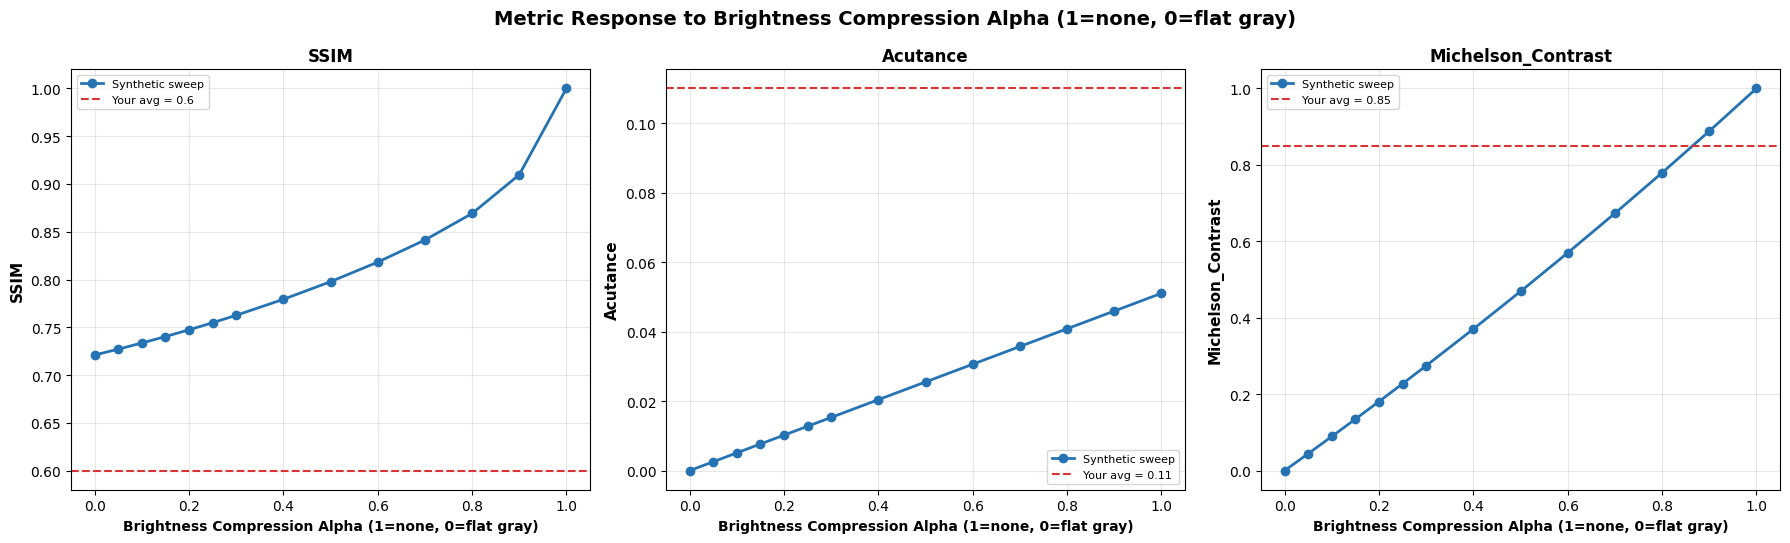

Saved plot to /content/drive/MyDrive/Master/Test parameters/calibration_noise.png


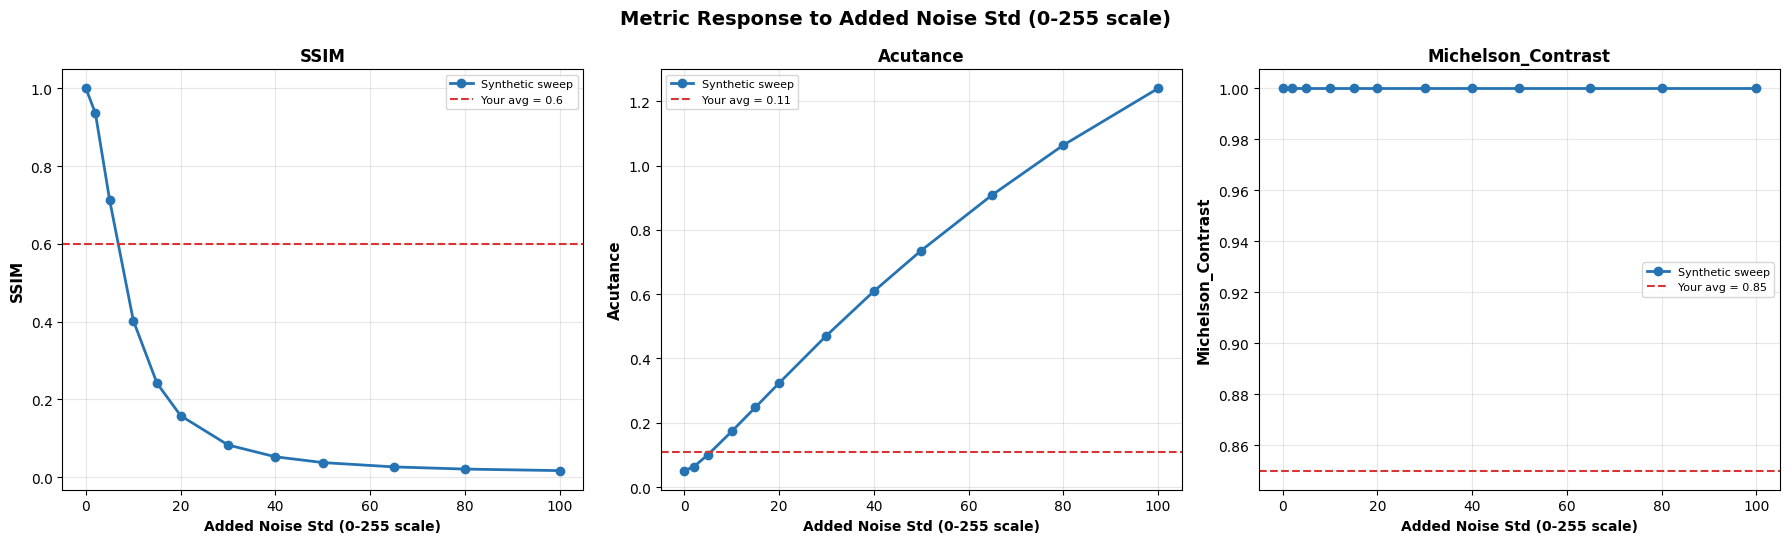

Saved plot to /content/drive/MyDrive/Master/Test parameters/calibration_combined.png


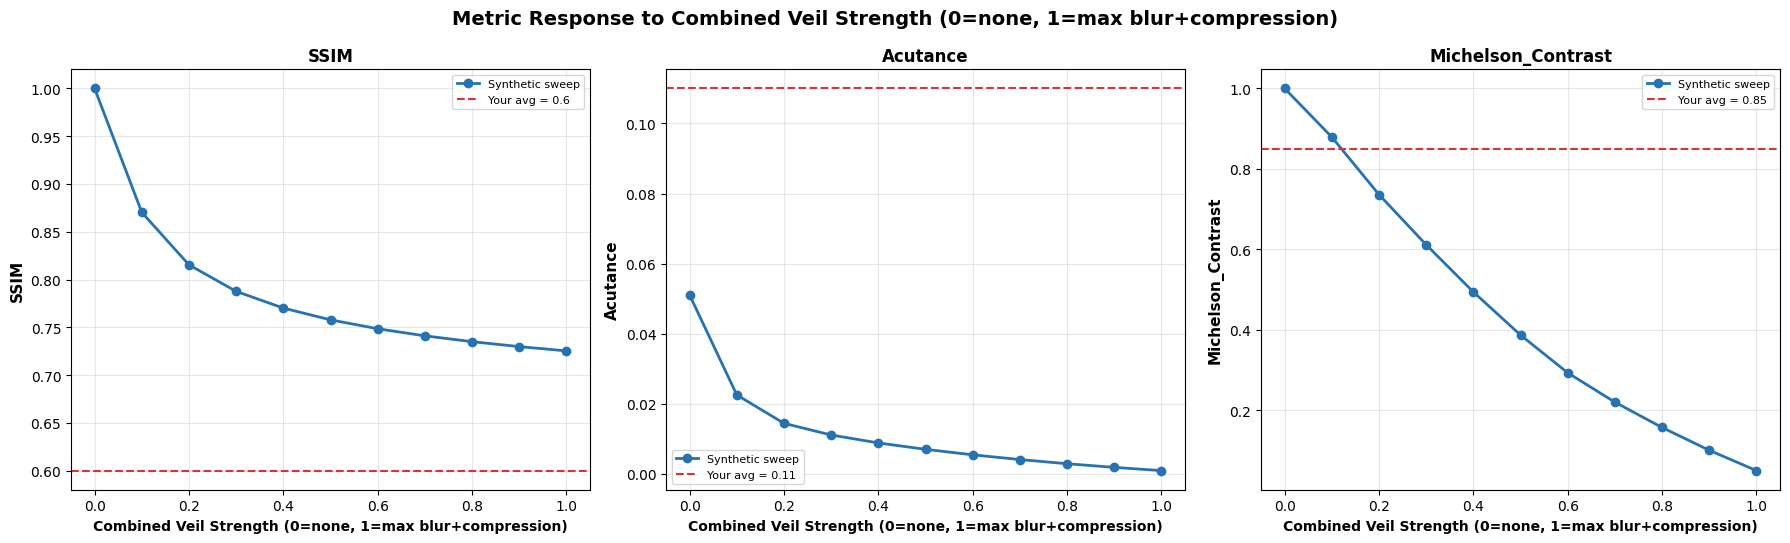

In [ ]:
"""
Calibration sweep: applies controlled, synthetic distortions to the
no-curtain reference image (known Gaussian blur sigma, known brightness
compression, known added noise std) and computes SSIM / Acutance /
Michelson Contrast for each -- exactly the same metric functions used in
the main pipeline. Plotting each metric against distortion strength gives
a "ruler" for what a given metric value actually corresponds to, and is a
methodology-validation figure showing the metrics respond sensibly to
known ground-truth distortions.

Uses the SAME metric formulas as code_55samples.py: mean-normalized SSIM
with DynamicRange taken from the reference crop, Sobel-based Acutance,
and Michelson contrast -- all on the same ROI.
"""

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REF_FILENAME = "/content/drive/MyDrive/Master/All images/No fabric cabinet.JPG"
IMAGE_DIR    = "/content/drive/MyDrive/Master/All images"

OUTPUT_DIR = "/content/drive/MyDrive/Master/Test parameters"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Same ROI proportions as the main pipeline
ROI_FRAC = dict(x=0.25, y=0.52, w=0.50, h=0.40)

# Distortion sweeps -- edit ranges/steps as needed
BLUR_SIGMAS        = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 13, 16, 20, 25]
COMPRESSION_ALPHAS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05, 0.0]
NOISE_STDS         = [0, 2, 5, 10, 15, 20, 30, 40, 50, 65, 80, 100]
COMBINED_STRENGTHS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # veil strength t

# Your actual measured averages across real fabric samples -- drawn as a
# horizontal reference line on each plot, and used to interpolate the
# "equivalent distortion strength" for each metric.
YOUR_AVERAGES = {
    'SSIM': 0.60,
    'Acutance': 0.11,
    'Michelson_Contrast': 0.85,
}

# ---------------------------------------------------------------
# HELPERS (same as code_55samples.py)
# ---------------------------------------------------------------
def imread_gray(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)


def compute_roi(img_shape, frac=ROI_FRAC):
    h, w = img_shape
    x = round(w * frac["x"])
    y = round(h * frac["y"])
    rw = round(w * frac["w"])
    rh = round(h * frac["h"])
    return x, y, rw, rh


def crop(img, roi):
    x, y, rw, rh = roi
    return img[y:y + rh, x:x + rw]


def compute_metrics(img_roi_scaled, ref_roi_norm):
    """img_roi_scaled: distorted crop scaled to [0,1] (NOT mean-normalized yet).
    Returns (ssim, acutance, contrast), matching code_55samples.py exactly."""
    img_roi_norm = img_roi_scaled / np.mean(img_roi_scaled)

    dyn_range = ref_roi_norm.max() - ref_roi_norm.min()
    ssim_val = ssim_func(img_roi_norm, ref_roi_norm, data_range=dyn_range,
                          gaussian_weights=True, sigma=1.5,
                          use_sample_covariance=False)

    gx = cv2.Sobel(img_roi_scaled, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_roi_scaled, cv2.CV_64F, 0, 1, ksize=3)
    gmag = np.sqrt(gx**2 + gy**2)
    acutance_val = np.mean(gmag)

    contrast_val = (img_roi_scaled.max() - img_roi_scaled.min()) / \
                   (img_roi_scaled.max() + img_roi_scaled.min())

    return ssim_val, acutance_val, contrast_val


# ---------------------------------------------------------------
# LOAD REFERENCE, DEFINE ROI
# ---------------------------------------------------------------
ref_path = os.path.join(IMAGE_DIR, REF_FILENAME)
ref_img = imread_gray(ref_path)
roi = compute_roi(ref_img.shape)

# Crop ONCE up front -- distortions are applied to this small crop directly,
# not to the full-resolution image. Blurring a full multi-megapixel photo
# on every sweep step (especially at large sigma, where the kernel gets
# huge) is what caused the severe slowdown/hang at sigma >= 13.
ref_roi_raw = crop(ref_img, roi)

ref_roi_scaled = ref_roi_raw / 255.0
ref_roi_norm = ref_roi_scaled / np.mean(ref_roi_scaled)

# ---------------------------------------------------------------
# DISTORTION FUNCTIONS
# ---------------------------------------------------------------
def apply_blur(img, sigma):
    if sigma <= 0:
        return img.copy()
    ksize = int(2 * round(3 * sigma) + 1)  # odd kernel size covering ~3 sigma
    return cv2.GaussianBlur(img, (ksize, ksize), sigma)


def apply_compression(img, alpha):
    """alpha=1.0 -> unchanged; alpha->0 -> collapses toward mid-gray (128)."""
    return 128.0 + alpha * (img - 128.0)


def apply_noise(img, std, seed=0):
    if std <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, std, img.shape)
    return np.clip(img + noise, 0, 255)


# Combined "veil strength" sweep: a single parameter t in [0, 1] scales
# BOTH blur sigma and compression alpha together, since neither distortion
# alone reliably brackets a real curtain's SSIM range -- blur plateaus once
# a low-texture ROI runs out of detail to remove, and compression's effect
# on SSIM gets partly cancelled by the mean-normalization step above.
# Combining them is closer to what a real fabric actually does: it softens
# edges a little AND compresses contrast substantially, at the same time.
MAX_COMBINED_SIGMA = 15    # blur sigma at t=1
MIN_COMBINED_ALPHA = 0.1   # compression alpha at t=1 (not 0, to avoid a fully flat/degenerate image)


def apply_combined(img, t):
    sigma = t * MAX_COMBINED_SIGMA
    alpha = 1.0 - t * (1.0 - MIN_COMBINED_ALPHA)
    blurred = apply_blur(img, sigma)
    return apply_compression(blurred, alpha)


def find_equivalent_param(sweep_df, param_col, metric_col, target):
    """
    Interpolate the distortion parameter value at which `metric_col` would
    equal `target`, given the swept (param, metric) points. Returns None
    if target falls outside the range actually covered by the sweep.
    """
    params = sweep_df[param_col].to_numpy()
    values = sweep_df[metric_col].to_numpy()

    order = np.argsort(values)
    values_sorted = values[order]
    params_sorted = params[order]

    if target < values_sorted.min() or target > values_sorted.max():
        return None

    return float(np.interp(target, values_sorted, params_sorted))


def interp_metric_at_param(sweep_df, param_col, metric_col, param_value):
    """Given a specific (possibly interpolated) parameter value, interpolate
    what `metric_col` would be there -- the reverse direction of
    find_equivalent_param, used to cross-check the OTHER metrics at a point
    solved for one particular metric."""
    params = sweep_df[param_col].to_numpy()
    values = sweep_df[metric_col].to_numpy()
    order = np.argsort(params)
    return float(np.interp(param_value, params[order], values[order]))


# ---------------------------------------------------------------
# RUN SWEEPS
# ---------------------------------------------------------------
def run_sweep(distort_fn, param_values, param_name):
    rows = []
    for val in param_values:
        distorted_roi = distort_fn(ref_roi_raw, val)
        img_roi_scaled = distorted_roi / 255.0
        ssim_val, acutance_val, contrast_val = compute_metrics(img_roi_scaled, ref_roi_norm)
        rows.append({
            param_name: val,
            'SSIM': ssim_val,
            'Acutance': acutance_val,
            'Michelson_Contrast': contrast_val,
        })
        print(f"{param_name}={val:<8}  SSIM={ssim_val:.4f}  "
              f"Acutance={acutance_val:.2f}  Contrast={contrast_val:.4f}")
    return pd.DataFrame(rows)


print("=== Blur sweep ===")
blur_df = run_sweep(apply_blur, BLUR_SIGMAS, 'Blur_sigma')

print("\n=== Brightness compression sweep ===")
compression_df = run_sweep(apply_compression, COMPRESSION_ALPHAS, 'Compression_alpha')

print("\n=== Noise sweep ===")
noise_df = run_sweep(apply_noise, NOISE_STDS, 'Noise_std')

print("\n=== Combined blur+compression (veil strength) sweep ===")
combined_df = run_sweep(apply_combined, COMBINED_STRENGTHS, 'Veil_strength')

# ---------------------------------------------------------------
# READOUT: what distortion strength corresponds to YOUR real averages?
# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("  EQUIVALENT DISTORTION STRENGTH FOR YOUR REAL AVERAGE METRIC VALUES")
print("=" * 70)

sweep_lookup = [
    (blur_df, 'Blur_sigma', 'blur sigma'),
    (compression_df, 'Compression_alpha', 'compression alpha'),
    (noise_df, 'Noise_std', 'noise std'),
    (combined_df, 'Veil_strength', 'veil strength'),
]

for metric, target in YOUR_AVERAGES.items():
    print(f"\n{metric} = {target}:")
    for sweep_df, param_col, param_label in sweep_lookup:
        equiv = find_equivalent_param(sweep_df, param_col, metric, target)
        if equiv is not None:
            print(f"  ~ equivalent to {param_label} = {equiv:.2f}")
        else:
            print(f"  (outside the range covered by the {param_label} sweep -- widen that range to bracket it)")

# ---------------------------------------------------------------
# CROSS-CHECK: does the parameter that matches ONE metric also match
# the OTHER TWO real averages? A sweep type that's consistent across
# all three metrics at a single parameter value is much stronger
# evidence of the real distortion mechanism than matching one metric
# in isolation.
# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("  CROSS-CHECK: ANCHOR ON ONE METRIC, PREDICT THE OTHER TWO")
print("=" * 70)

metric_names_list = list(YOUR_AVERAGES.keys())

for sweep_df, param_col, param_label in sweep_lookup:
    print(f"\n--- {param_label} sweep ---")
    for anchor_metric in metric_names_list:
        anchor_target = YOUR_AVERAGES[anchor_metric]
        equiv_param = find_equivalent_param(sweep_df, param_col, anchor_metric, anchor_target)
        if equiv_param is None:
            print(f"  Anchored on {anchor_metric}={anchor_target}: outside range, skipped")
            continue

        other_metrics = [m for m in metric_names_list if m != anchor_metric]
        predictions = []
        for other in other_metrics:
            predicted = interp_metric_at_param(sweep_df, param_col, other, equiv_param)
            real = YOUR_AVERAGES[other]
            diff = predicted - real
            predictions.append(f"{other}: predicted={predicted:.3f} vs real={real:.3f} (diff={diff:+.3f})")

        print(f"  Anchored on {anchor_metric}={anchor_target} -> {param_label}={equiv_param:.2f}")
        for line in predictions:
            print(f"      {line}")

# ---------------------------------------------------------------
# SAVE RESULTS
# ---------------------------------------------------------------
report_path = os.path.join(OUTPUT_DIR, "calibration_sweep_report.xlsx")
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    blur_df.to_excel(writer, sheet_name="Blur sweep", index=False)
    compression_df.to_excel(writer, sheet_name="Compression sweep", index=False)
    noise_df.to_excel(writer, sheet_name="Noise sweep", index=False)
    combined_df.to_excel(writer, sheet_name="Combined sweep", index=False)

print(f"\nSaved report to {report_path}")

# ---------------------------------------------------------------
# PLOTS -- one figure per distortion type, 3 subplots (one per metric)
# ---------------------------------------------------------------
metric_names = ['SSIM', 'Acutance', 'Michelson_Contrast']

sweeps = [
    (blur_df, 'Blur_sigma', 'Gaussian Blur Sigma (px)', 'blur'),
    (compression_df, 'Compression_alpha', 'Brightness Compression Alpha (1=none, 0=flat gray)', 'compression'),
    (noise_df, 'Noise_std', 'Added Noise Std (0-255 scale)', 'noise'),
    (combined_df, 'Veil_strength', 'Combined Veil Strength (0=none, 1=max blur+compression)', 'combined'),
]

for sweep_df, param_col, x_label, tag in sweeps:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    fig.suptitle(f"Metric Response to {x_label}", fontsize=14, fontweight='bold')

    for ax, metric in zip(axes, metric_names):
        ax.plot(sweep_df[param_col], sweep_df[metric], marker='o',
                color=(0.15, 0.45, 0.70), linewidth=2, label='Synthetic sweep')

        target = YOUR_AVERAGES.get(metric)
        if target is not None:
            ax.axhline(target, color=(0.85, 0.20, 0.20), linestyle='--', linewidth=1.5,
                       label=f'Your avg = {target}')
            ax.legend(fontsize=8)

        ax.set_xlabel(x_label, fontsize=10, fontweight='bold')
        ax.set_ylabel(metric, fontsize=11, fontweight='bold')
        ax.set_title(metric, fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plot_path = os.path.join(OUTPUT_DIR, f"calibration_{tag}.png")
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    print(f"Saved plot to {plot_path}")
    plt.show()

### Calibration paths

These settings mirror the configuration in the calibration cell. Edit the paths inside that cell when rerunning the sweep.

In [ ]:
REF_FILENAME = "/content/drive/MyDrive/Master/All images/No fabric cabinet.JPG"
IMAGE_DIR    = "/content/drive/MyDrive/Master/All images"

OUTPUT_DIR = "/content/drive/MyDrive/Master/Test parameters"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3. Explore the full dataset

These analyses read the `Per-Sample Values` sheet in `all_report.xlsx`.

### Pairwise correlations and residuals

Compute correlations across all six optical and image metrics and plot the 15 unique pairs.

Loaded 55 samples

         FULL CORRELATION MATRIX: ALL OPTICAL & IMAGE PARAMETERS      
                             | T_dir                  | Diffuseness Ratio      | Opacity (R_b/R_w)      | SSIM                   | Acutance               | Michelson Contrast    
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
T_dir                        | --                     | -0.775* (p=0.000) [STRONG] | -0.629* (p=0.000)      | +0.310* (p=0.021)      | -0.255  (p=0.060)      | +0.277* (p=0.040)     
Diffuseness Ratio            | -0.775* (p=0.000) [STRONG] | --                     | +0.466* (p=0.000)      | +0.148  (p=0.282)      | -0.086  (p=0.532)      | -0.482* (p=0.000)     
Opacity (R_b/R_w)            | -0.629* (p=0.000)      | +0.466* (p=0.000)      | --                     | +0.205  (p=0.134)      | -0.248  (p=0.068)      | -0.562* (p=0.000)     
SSIM 

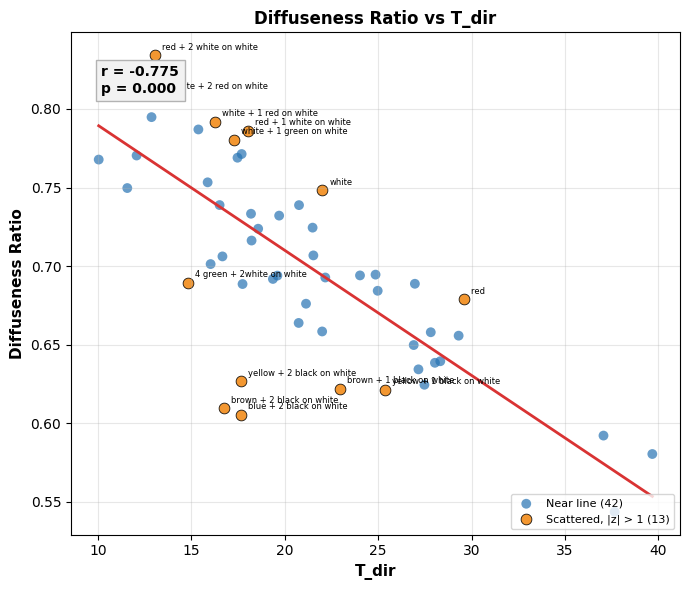

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_T_dir_vs_Opacity_R_b_R_w_.png


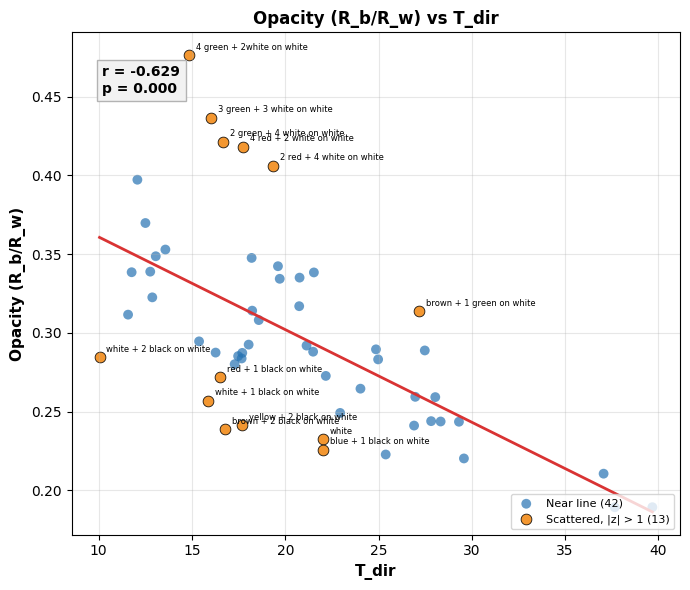

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_T_dir_vs_SSIM.png


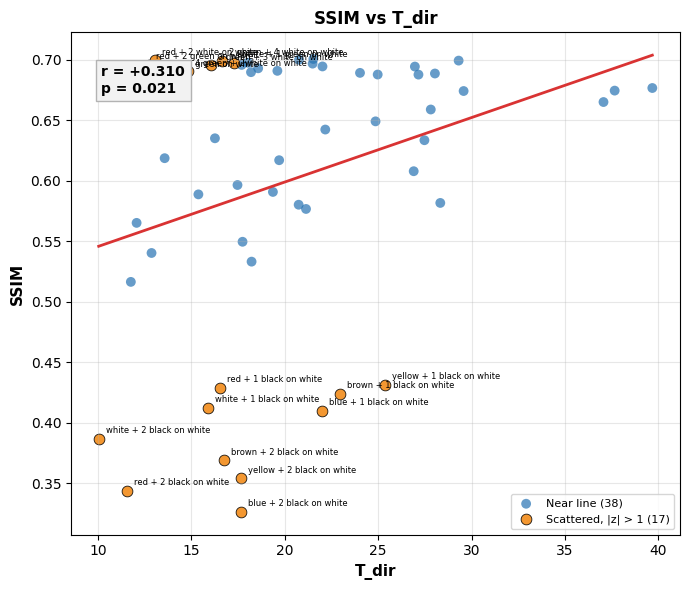

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_T_dir_vs_Acutance.png


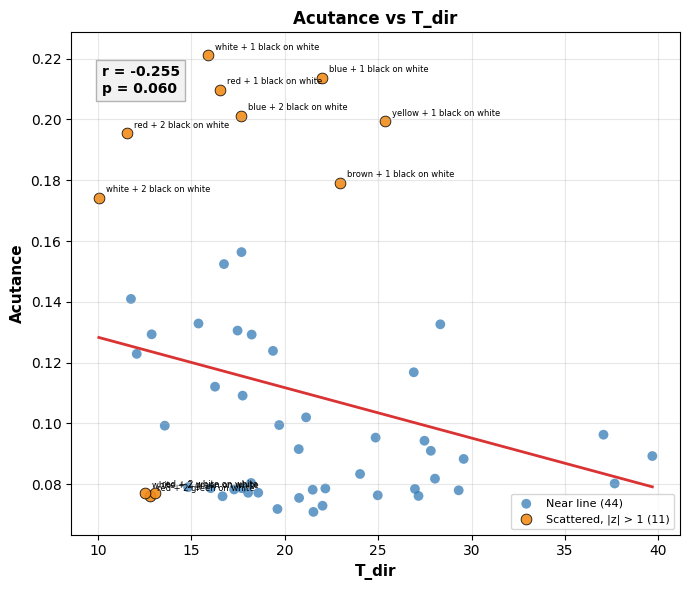

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_T_dir_vs_Michelson_Contrast.png


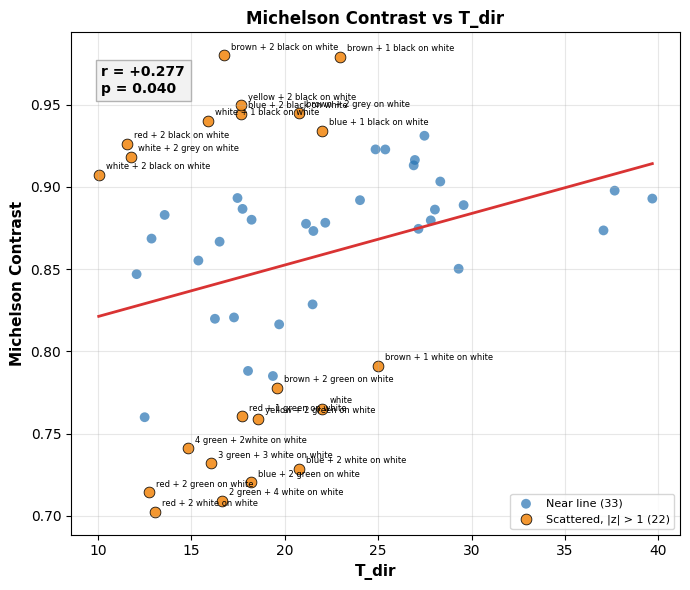

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Diffuseness_Ratio_vs_Opacity_R_b_R_w_.png


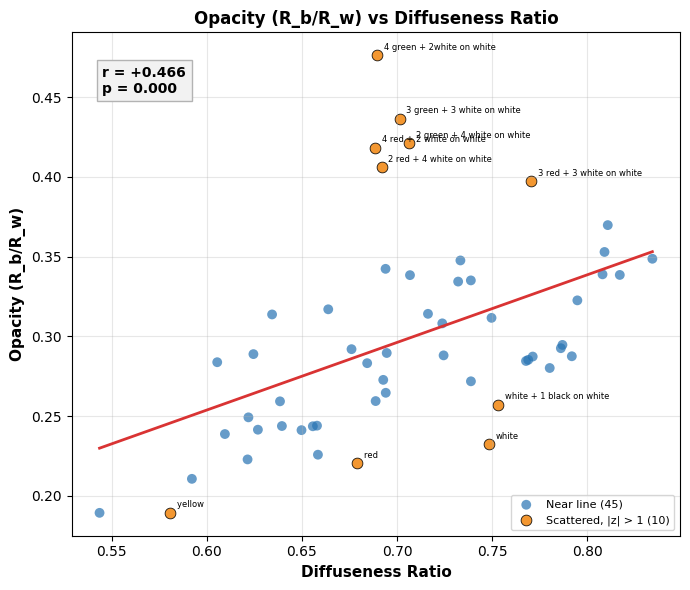

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Diffuseness_Ratio_vs_SSIM.png


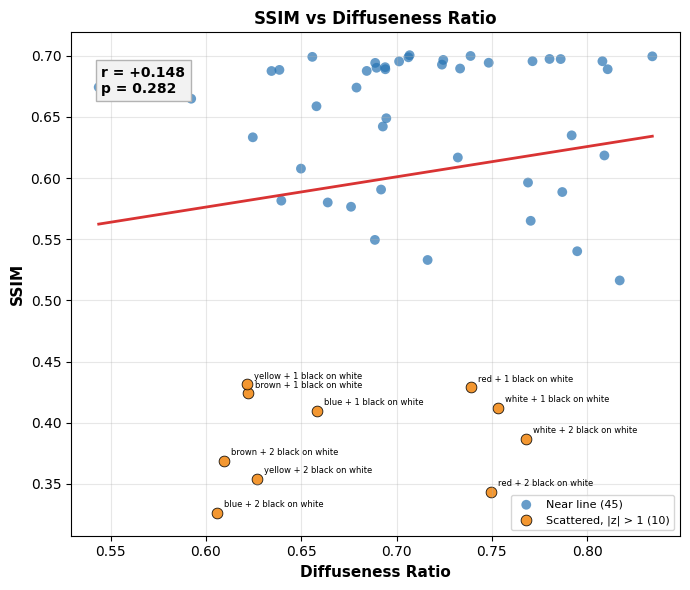

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Diffuseness_Ratio_vs_Acutance.png


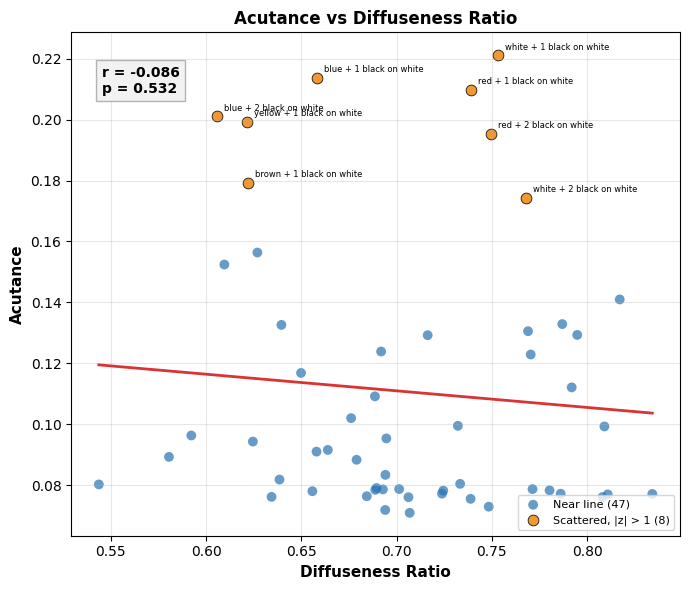

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Diffuseness_Ratio_vs_Michelson_Contrast.png


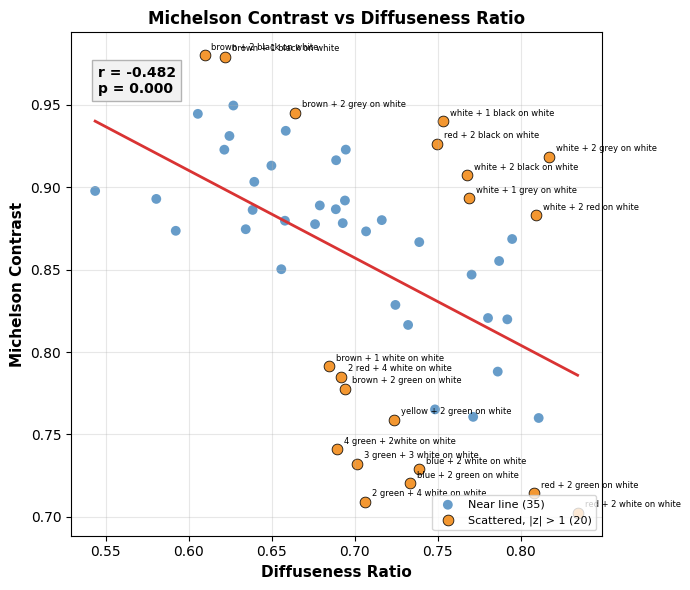

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Opacity_R_b_R_w__vs_SSIM.png


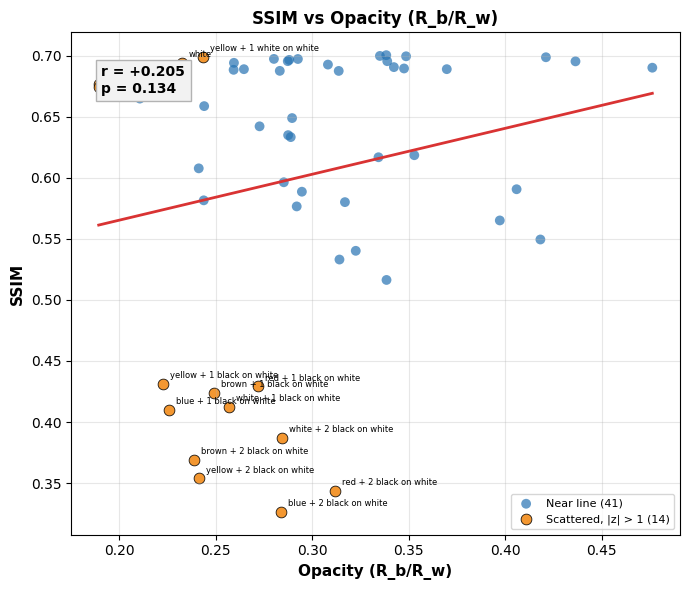

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Opacity_R_b_R_w__vs_Acutance.png


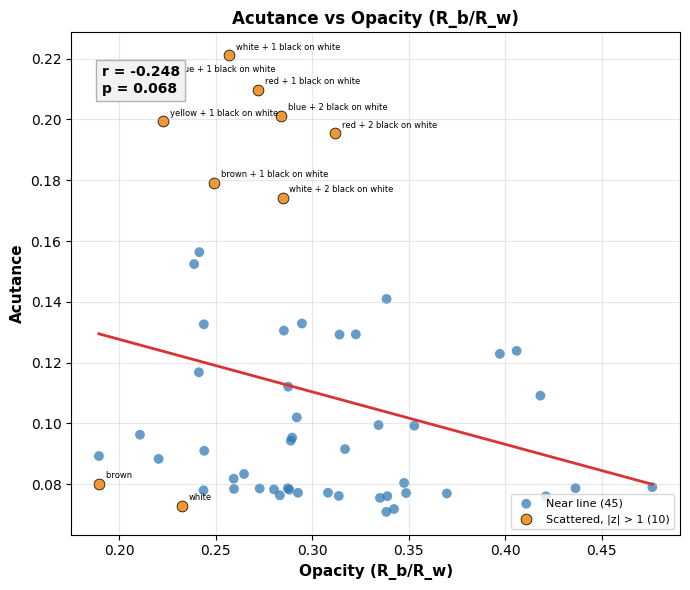

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Opacity_R_b_R_w__vs_Michelson_Contrast.png


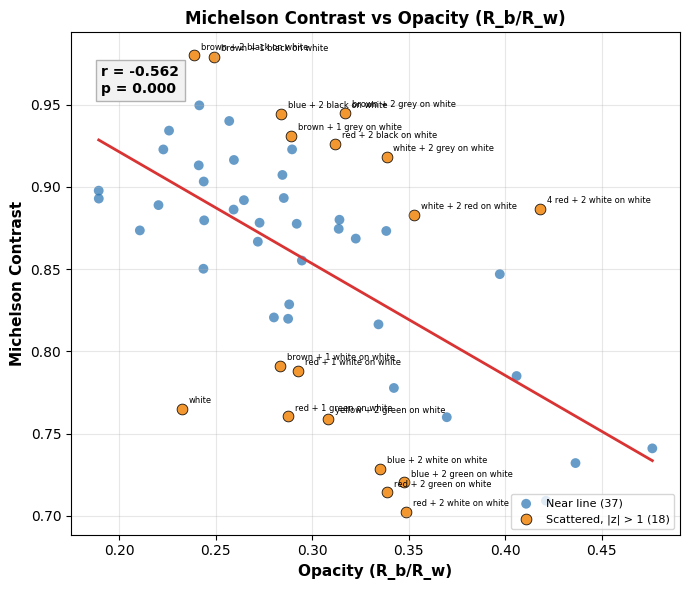

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_SSIM_vs_Acutance.png


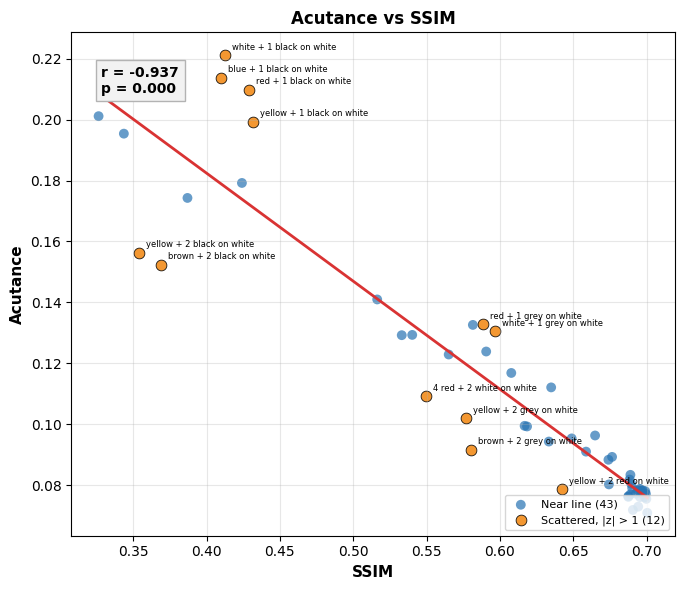

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_SSIM_vs_Michelson_Contrast.png


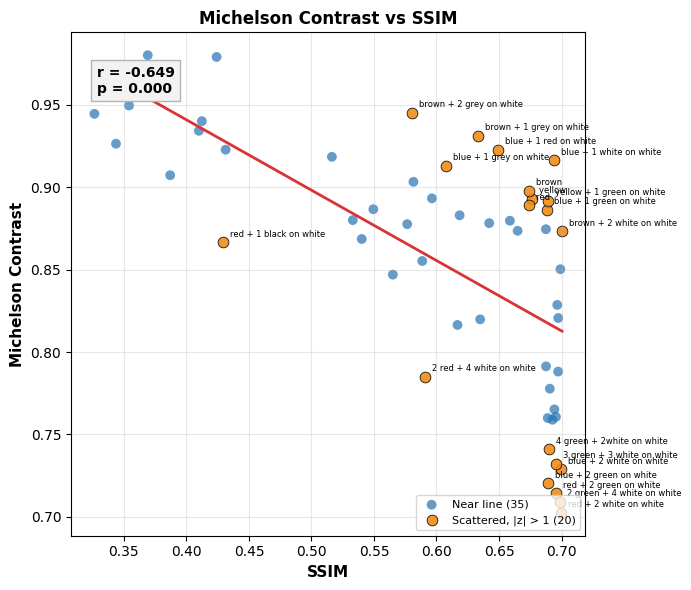

Saved plot to /content/drive/MyDrive/Master/All data report/Complete correlation/plot_Acutance_vs_Michelson_Contrast.png


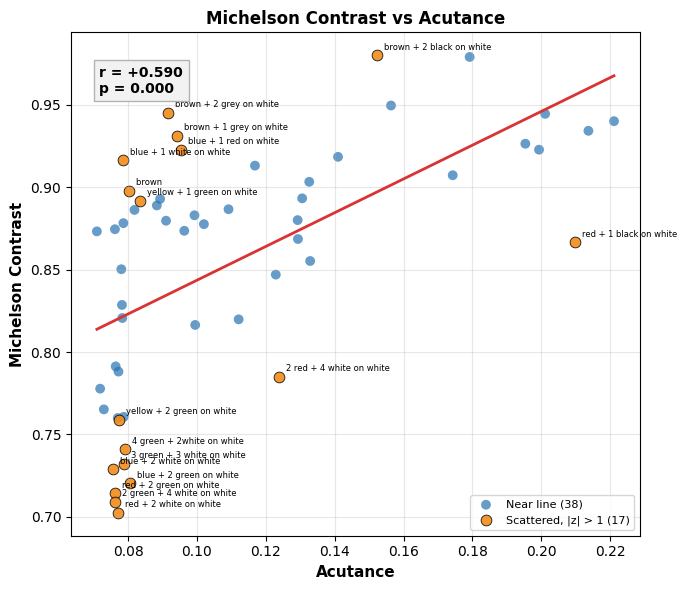


  SAMPLES RANKED BY HOW OFTEN THEY FALL OFF THE REGRESSION LINE
  (scattered = |residual| > 1 SD, out of 15 pairs)
                            Scattered_in  Total_pairs  Scattered_pct
Sample                                                              
white + 1 black on white              11           15           73.3
brown + 1 black on white              10           15           66.7
brown + 2 black on white              10           15           66.7
red + 1 black on white                10           15           66.7
red + 2 black on white                 9           15           60.0
blue + 2 black on white                9           15           60.0
blue + 1 black on white                9           15           60.0
white + 2 black on white               9           15           60.0
4 green + 2white on white              8           15           53.3
red + 2 white on white                 8           15           53.3
yellow + 1 black on white              8           15   

In [ ]:
"""
Full correlation comparison among ALL SIX parameters -- the 3 optical
predictors (T_dir, Diffuseness Ratio, Opacity) AND the 3 image metrics
(SSIM, Acutance, Michelson Contrast) -- including within-group pairs
(e.g. T_dir vs Diffuseness, SSIM vs Acutance), not just predictor-vs-metric.

Reads from the report already saved by the main script
(fabric_analysis_report.xlsx, sheet "Per-Sample Values") -- doesn't
recompute anything, just re-analyzes what's already there.
"""

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"
SHEET_NAME  = "Per-Sample Values"

OUTPUT_DIR = "/content/drive/MyDrive/Master/All data report/Complete correlation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

r_threshold = 0.70
p_threshold = 0.05

# A sample counts as "scattered" for a given pair if its distance from the
# regression line exceeds this many residual standard deviations; otherwise
# it counts as "near the line". 1.0 is strict (flags roughly a third of
# points even for well-behaved data) -- raise to 1.5 or 2.0 to flag only
# clear outliers.
RESIDUAL_SD_THRESHOLD = 1.0

# (column name in the report, display name for tables/plots)
PARAMS = [
    ('weighted_T_dir',      'T_dir'),
    ('diffuseness',         'Diffuseness Ratio'),
    ('opacity',             'Opacity (R_b/R_w)'),
    ('SSIM',                'SSIM'),
    ('Acutance',            'Acutance'),
    ('Michelson_Contrast',  'Michelson Contrast'),
]

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)

col_names = [c for c, _ in PARAMS]
display_names = [d for _, d in PARAMS]
n_params = len(PARAMS)

data = df[col_names].to_numpy()
sample_names = df['Sample'].tolist()

print(f"Loaded {len(df)} samples")

# ---------------------------------------------------------------
# FULL 6x6 CORRELATION MATRIX (pairwise NaN handling)
# ---------------------------------------------------------------
R_matrix = np.full((n_params, n_params), np.nan)
P_values = np.full((n_params, n_params), np.nan)

for i in range(n_params):
    for j in range(n_params):
        if i == j:
            continue
        x, y = data[:, i], data[:, j]
        mask = ~np.isnan(x) & ~np.isnan(y)
        if mask.sum() > 1:
            r, p = pearsonr(x[mask], y[mask])
            R_matrix[i, j] = r
            P_values[i, j] = p

# ---------------------------------------------------------------
# PRINT FORMATTED TABLE (same style as the main script)
# ---------------------------------------------------------------
print("\n" + "=" * (30 + 25 * n_params))
print("         FULL CORRELATION MATRIX: ALL OPTICAL & IMAGE PARAMETERS      ")
print("=" * (30 + 25 * n_params))

header = f"{'':<28} | " + " | ".join(f"{name:<22}" for name in display_names)
print(header)
print("-" * (30 + 25 * n_params))

for i in range(n_params):
    row = f"{display_names[i]:<28} | "
    cells = []
    for j in range(n_params):
        if i == j:
            cells.append(f"{'--':<22}")
            continue
        r_val, p_val = R_matrix[i, j], P_values[i, j]
        sig_flag = '*' if p_val < p_threshold else ' '
        if abs(r_val) >= r_threshold:
            cell_str = f"{r_val:+6.3f}{sig_flag} (p={p_val:.3f}) [STRONG]"
        else:
            cell_str = f"{r_val:+6.3f}{sig_flag} (p={p_val:.3f})"
        cells.append(f"{cell_str:<22}")
    print(row + " | ".join(cells))

print("=" * (30 + 25 * n_params))
print(f"Notes: [STRONG] indicates strong correlation (|r| >= {r_threshold:.2f}). "
      f"* denotes p < {p_threshold:.2f}. '--' = self-pair, skipped.\n")

# ---------------------------------------------------------------
# SEPARATE SCATTER PLOT FOR EVERY UNIQUE PAIR (15 total, i < j)
# Points near the regression line are blue; scattered points (residual
# beyond RESIDUAL_SD_THRESHOLD) are orange and labeled with sample name.
# ---------------------------------------------------------------
scatter_color = (0.15, 0.45, 0.70)   # near the line
outlier_color = (0.95, 0.55, 0.10)   # scattered
line_color    = (0.85, 0.20, 0.20)

sample_arr = np.array(sample_names)
residual_rows = []

for i in range(n_params):
    for j in range(i + 1, n_params):
        x = data[:, i]
        y = data[:, j]
        mask = ~np.isnan(x) & ~np.isnan(y)
        x_clean, y_clean = x[mask], y[mask]
        names_clean = sample_arr[mask]

        r_val, p_val = R_matrix[i, j], P_values[i, j]
        pair_label = f"{display_names[j]} vs {display_names[i]}"

        # Distance of each sample from the regression line, in units of
        # residual standard deviation (ddof=2: slope and intercept fitted)
        p_fit = np.polyfit(x_clean, y_clean, 1)
        residuals = y_clean - np.polyval(p_fit, x_clean)
        z = residuals / residuals.std(ddof=2)
        scattered = np.abs(z) > RESIDUAL_SD_THRESHOLD

        for name, xv, yv, res, zv, sc in zip(names_clean, x_clean, y_clean, residuals, z, scattered):
            residual_rows.append({
                'Pair': pair_label,
                'Sample': name,
                'X_param': display_names[i],
                'X_value': xv,
                'Y_param': display_names[j],
                'Y_value': yv,
                'Residual': res,
                'Std_Residual': zv,
                'Status': 'Scattered' if sc else 'Near line',
            })

        fig, ax = plt.subplots(figsize=(7, 6))
        ax.scatter(x_clean[~scattered], y_clean[~scattered], s=50, color=scatter_color,
                   alpha=0.7, edgecolor='none', label=f'Near line ({(~scattered).sum()})')
        ax.scatter(x_clean[scattered], y_clean[scattered], s=60, color=outlier_color,
                   alpha=0.9, edgecolor='black', linewidth=0.6,
                   label=f'Scattered, |z| > {RESIDUAL_SD_THRESHOLD:g} ({scattered.sum()})')

        x_fit = np.linspace(x_clean.min(), x_clean.max(), 100)
        ax.plot(x_fit, np.polyval(p_fit, x_fit), color=line_color, linewidth=2)

        # label only the scattered samples, to keep the plot readable
        for name, xv, yv in zip(names_clean[scattered], x_clean[scattered], y_clean[scattered]):
            ax.annotate(str(name), (xv, yv), textcoords="offset points",
                        xytext=(5, 4), fontsize=6)

        stats_str = f"r = {r_val:+0.3f}\np = {p_val:0.3f}"
        xl, yl = ax.get_xlim(), ax.get_ylim()
        ax.text(xl[0] + 0.05 * (xl[1] - xl[0]), yl[1] - 0.12 * (yl[1] - yl[0]),
                stats_str, fontsize=10, fontweight='bold',
                bbox=dict(facecolor=(0.95, 0.95, 0.95), edgecolor=(0.7, 0.7, 0.7)))

        ax.set_xlabel(display_names[i], fontsize=11, fontweight='bold')
        ax.set_ylabel(display_names[j], fontsize=11, fontweight='bold')
        ax.set_title(pair_label, fontsize=12, fontweight='bold')
        ax.legend(fontsize=8, loc='lower right')
        ax.grid(True, alpha=0.3)

        plt.tight_layout()

        safe_i = re.sub(r'[^\w\-]+', '_', display_names[i])
        safe_j = re.sub(r'[^\w\-]+', '_', display_names[j])
        plot_path = os.path.join(OUTPUT_DIR, f"plot_{safe_i}_vs_{safe_j}.png")
        plt.savefig(plot_path, dpi=150, bbox_inches='tight')
        print(f"Saved plot to {plot_path}")

        plt.show()

# ---------------------------------------------------------------
# PER-SAMPLE SUMMARY: how often was each sample scattered, across all pairs?
# A sample flagged in many pairs is a consistent outlier, not a one-off.
# ---------------------------------------------------------------
residual_df = pd.DataFrame(residual_rows)

sample_summary = (
    residual_df.assign(Is_Scattered=residual_df['Status'] == 'Scattered')
    .groupby('Sample')['Is_Scattered']
    .agg(Scattered_in='sum', Total_pairs='count')
    .assign(Scattered_pct=lambda d: 100 * d['Scattered_in'] / d['Total_pairs'])
    .sort_values('Scattered_in', ascending=False)
)

print("\n" + "=" * 70)
print(f"  SAMPLES RANKED BY HOW OFTEN THEY FALL OFF THE REGRESSION LINE")
print(f"  (scattered = |residual| > {RESIDUAL_SD_THRESHOLD:g} SD, out of {sample_summary['Total_pairs'].max()} pairs)")
print("=" * 70)
print(sample_summary.round(1).to_string())

# ---------------------------------------------------------------
# SAVE REPORT
# ---------------------------------------------------------------
correlation_table = pd.DataFrame(R_matrix, index=display_names, columns=display_names)
pvalue_table       = pd.DataFrame(P_values, index=display_names, columns=display_names)

report_path = os.path.join(OUTPUT_DIR, "full_correlation_report.xlsx")
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    correlation_table.to_excel(writer, sheet_name="Correlation (R)")
    pvalue_table.to_excel(writer, sheet_name="p-values")
    residual_df.to_excel(writer, sheet_name="Residuals per pair", index=False)
    sample_summary.to_excel(writer, sheet_name="Sample summary")

print(f"\nSaved report to {report_path}")

### Principal components and eigenvectors

Decompose the covariance matrix to examine how the six metrics vary together.

In [ ]:
"""
Eigen decomposition (PCA-style) of the 55-sample, 6-parameter dataset:
T_dir, Diffuseness Ratio, Opacity, SSIM, Acutance, Michelson Contrast.

Normalization: mean-centering is required for the eigenvectors to reflect
how the parameters co-vary rather than their raw offsets. Since the 6
parameters are on very different scales (T_dir ~15-30 vs Acutance ~0.01-0.3),
z-score standardization (subtract mean, divide by std) is used by default
-- NOT divide-by-max -- because max-normalization doesn't equalize
variance, so a naturally large-range variable would dominate the
eigenvectors purely due to scale. This is the difference between PCA on a
covariance matrix (mean-centered only) and PCA on a correlation matrix
(standardized) -- the standardized version is the right choice when
variables are in different units, which these are.

Reads from the report already saved by the main script
(fabric_analysis_report.xlsx, "Per-Sample Values").
"""

import numpy as np
import pandas as pd

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"
SHEET_NAME  = "Per-Sample Values"

OUTPUT_FILE = "/content/drive/MyDrive/Master/All data report/Eigenvectors/Eigenvectors.xlsx"

# 'zscore' (recommended, default): subtract mean, divide by std -- puts all
#          6 parameters on equal footing regardless of their original scale
# 'max':   subtract mean, divide by max absolute value -- your original
#          suggestion; kept as an option, but does NOT equalize variance
NORMALIZATION = 'zscore'

PARAMS = [
    ('weighted_T_dir',      'T_dir'),
    ('diffuseness',         'Diffuseness Ratio'),
    ('opacity',             'Opacity (R_b/R_w)'),
    ('SSIM',                'SSIM'),
    ('Acutance',            'Acutance'),
    ('Michelson_Contrast',  'Michelson Contrast'),
]

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)

col_names = [c for c, _ in PARAMS]
display_names = [d for _, d in PARAMS]

data_full = df[col_names].to_numpy()
sample_names_full = df['Sample'].tolist()

# Drop any sample with a NaN in any of the 6 parameters (e.g. a sample
# whose image never got matched) -- eigen decomposition needs complete rows.
valid_mask = ~np.isnan(data_full).any(axis=1)
data = data_full[valid_mask]
sample_names = [s for s, v in zip(sample_names_full, valid_mask) if v]

n_dropped = (~valid_mask).sum()
print(f"Loaded {len(df)} samples, using {len(data)} complete rows "
      f"({n_dropped} dropped for missing values)")

# ---------------------------------------------------------------
# NORMALIZE
# ---------------------------------------------------------------
means = data.mean(axis=0)
centered = data - means

if NORMALIZATION == 'zscore':
    scale = data.std(axis=0, ddof=1)   # sample std (ddof=1), matches covariance convention below
elif NORMALIZATION == 'max':
    scale = np.abs(centered).max(axis=0)
else:
    raise ValueError(f"Unknown NORMALIZATION: {NORMALIZATION!r} (use 'zscore' or 'max')")

normalized = centered / scale

print(f"\nNormalization method: {NORMALIZATION}")
print("Per-parameter mean (before centering):")
for name, m in zip(display_names, means):
    print(f"  {name:<22} mean={m:.4f}")
print("Per-parameter scale (std or max, per NORMALIZATION):")
for name, s in zip(display_names, scale):
    print(f"  {name:<22} scale={s:.4f}")

# ---------------------------------------------------------------
# COVARIANCE MATRIX (6x6) AND EIGEN DECOMPOSITION
# ---------------------------------------------------------------
# rowvar=False: each column is a variable, each row an observation
cov_matrix = np.cov(normalized, rowvar=False, ddof=1)

# eigh: covariance matrices are symmetric, so eigh is the correct (and more
# numerically stable) choice over the general eig -- returns eigenvalues
# in ASCENDING order, so we reverse both eigenvalues and eigenvectors to
# the conventional PCA order (largest variance first).
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]   # each COLUMN is one eigenvector

explained_variance_ratio = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)

# ---------------------------------------------------------------
# PRINT RESULTS
# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("  COVARIANCE MATRIX (6x6, normalized data)")
print("=" * 70)
cov_table = pd.DataFrame(cov_matrix, index=display_names, columns=display_names)
print(cov_table.round(4))

print("\n" + "=" * 70)
print("  EIGENVALUES AND EXPLAINED VARIANCE")
print("=" * 70)
for i, (ev, ratio, cum) in enumerate(zip(eigenvalues, explained_variance_ratio, cumulative_variance)):
    print(f"  PC{i+1}: eigenvalue={ev:.4f}   explained={ratio*100:5.2f}%   cumulative={cum*100:5.2f}%")

print("\n" + "=" * 70)
print("  EIGENVECTORS (each column is one principal component, PC1 first)")
print("=" * 70)
pc_labels = [f"PC{i+1}" for i in range(len(eigenvalues))]
eigvec_table = pd.DataFrame(eigenvectors, index=display_names, columns=pc_labels)
print(eigvec_table.round(4))

# ---------------------------------------------------------------
# SAVE REPORT
# ---------------------------------------------------------------
with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    cov_table.to_excel(writer, sheet_name="Covariance Matrix")
    eigvec_table.to_excel(writer, sheet_name="Eigenvectors")
    pd.DataFrame({
        'Eigenvalue': eigenvalues,
        'Explained_Variance_%': explained_variance_ratio * 100,
        'Cumulative_%': cumulative_variance * 100,
    }, index=pc_labels).to_excel(writer, sheet_name="Eigenvalues")

print(f"\nSaved report to {OUTPUT_FILE}")

Loaded 55 samples, using 55 complete rows (0 dropped for missing values)

Normalization method: zscore
Per-parameter mean (before centering):
  T_dir                  mean=20.6500
  Diffuseness Ratio      mean=0.7049
  Opacity (R_b/R_w)      mean=0.2983
  SSIM                   mean=0.6023
  Acutance               mean=0.1107
  Michelson Contrast     mean=0.8545
Per-parameter scale (std or max, per NORMALIZATION):
  T_dir                  scale=6.6555
  Diffuseness Ratio      scale=0.0684
  Opacity (R_b/R_w)      scale=0.0622
  SSIM                   scale=0.1144
  Acutance               scale=0.0433
  Michelson Contrast     scale=0.0752

  COVARIANCE MATRIX (6x6, normalized data)
                     T_dir  Diffuseness Ratio  Opacity (R_b/R_w)    SSIM  \
T_dir               1.0000            -0.7745            -0.6291  0.3100   
Diffuseness Ratio  -0.7745             1.0000             0.4661  0.1478   
Opacity (R_b/R_w)  -0.6291             0.4661             1.0000  0.2045   
SSIM  

### Correlation sensitivity to sample removal

Explore which sample removals raise the absolute correlation for each pair. The results describe sensitivity to sample selection.

In [ ]:
"""
For every pair among the 6 parameters, find which samples -- if removed --
would push |r| above R_TARGET.

Method: greedy leave-one-out. At each step, test removing each remaining
sample one at a time, keep whichever single removal increases |r| the
most, repeat until the target is reached or a stopping limit is hit. This
is NOT an exhaustive search for the smallest possible removal set (that's
combinatorially infeasible for 55 samples) -- it's the standard practical
approach, and the result should be read as "a reasonable set of samples
to look at", not "the unique minimal set".

Only needs the Excel report already produced by the main pipeline
(fabric_analysis_report.xlsx, "Per-Sample Values") -- no image data.
"""

import os
import itertools
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"
SHEET_NAME  = "Per-Sample Values"

OUTPUT_FILE = "/content/drive/MyDrive/Master/All data report/Finding outliers/outlier_removal_report.xlsx"

R_TARGET = 0.70            # push |r| above this
MAX_REMOVAL_FRACTION = 0.30  # never remove more than this fraction of samples
MIN_REMAINING = 10           # never let fewer than this many samples remain

# Checking every possible removal set up to this size is cheap enough to
# run exhaustively (e.g. with 55 samples, size <=3 is ~28,000 combinations
# per pair, well under a second). Within this size, the result is a
# PROVEN minimal count, not greedy's upper-bound estimate. Raise with
# caution -- size 4 is ~370,000 combinations per pair (still fine), size
# 5 is ~3.1 million per pair (slow across 15 pairs), size 6+ is impractical.
EXHAUSTIVE_MAX_K = 3

PARAMS = [
    ('weighted_T_dir',      'T_dir'),
    ('diffuseness',         'Diffuseness Ratio'),
    ('opacity',             'Opacity (R_b/R_w)'),
    ('SSIM',                'SSIM'),
    ('Acutance',            'Acutance'),
    ('Michelson_Contrast',  'Michelson Contrast'),
]

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)

col_names = [c for c, _ in PARAMS]
display_names = [d for _, d in PARAMS]
n_params = len(PARAMS)

print(f"Loaded {len(df)} samples")

# ---------------------------------------------------------------
# GREEDY REMOVAL FOR ONE PAIR
# ---------------------------------------------------------------
def greedy_removal(x, y, names, r_target, max_removals, min_remaining):
    """
    x, y, names: 1D arrays already filtered to non-NaN rows for this pair.
    Returns: (removed_list, final_r, final_p, reached_target: bool)
    removed_list is a list of (sample_name, r_after_removing_it) in the
    order they were removed.
    """
    remaining = np.ones(len(x), dtype=bool)
    removed_list = []

    r0, p0 = pearsonr(x, y)
    if abs(r0) >= r_target:
        return [], r0, p0, True  # already above target, nothing to remove

    for _ in range(max_removals):
        idx_remaining = np.where(remaining)[0]
        if len(idx_remaining) - 1 < min_remaining:
            break  # removing one more would breach the minimum sample floor

        best_idx = None
        best_r = None
        for idx in idx_remaining:
            trial = remaining.copy()
            trial[idx] = False
            r, _ = pearsonr(x[trial], y[trial])
            if best_r is None or abs(r) > abs(best_r):
                best_r = r
                best_idx = idx

        remaining[best_idx] = False
        removed_list.append((names[best_idx], best_r))

        if abs(best_r) >= r_target:
            r_final, p_final = pearsonr(x[remaining], y[remaining])
            return removed_list, r_final, p_final, True

    # exhausted the removal budget without reaching target
    r_final, p_final = pearsonr(x[remaining], y[remaining]) if remaining.sum() > 1 else (np.nan, np.nan)
    return removed_list, r_final, p_final, False


def exhaustive_removal(x, y, names, r_target, max_k):
    """
    Check EVERY possible removal set of size 1..max_k, smallest first.
    Returns (removed_tuple, r_after, found: bool) for the first size at
    which ANY combination reaches r_target -- among ties at that size,
    the one achieving the largest |r| is kept. This is a proven minimal
    count within max_k, unlike greedy_removal's upper-bound estimate.
    Returns found=False if no combination up to max_k reaches the target
    (which does NOT mean impossible -- only that nothing at size <= max_k
    works; a larger removal might still succeed, as greedy may show).
    """
    n = len(x)
    for k in range(1, max_k + 1):
        best_combo = None
        best_r = None
        for combo in itertools.combinations(range(n), k):
            mask = np.ones(n, dtype=bool)
            mask[list(combo)] = False
            r, _ = pearsonr(x[mask], y[mask])
            if abs(r) >= r_target and (best_r is None or abs(r) > abs(best_r)):
                best_r = r
                best_combo = combo
        if best_combo is not None:
            removed_names = tuple(names[i] for i in best_combo)
            return removed_names, best_r, True
    return (), None, False


# ---------------------------------------------------------------
# RUN FOR EVERY PAIR
# ---------------------------------------------------------------
results_rows = []
detail_rows = []

for i in range(n_params):
    for j in range(i + 1, n_params):
        x_col, y_col = col_names[i], col_names[j]
        x_name, y_name = display_names[i], display_names[j]

        sub = df[[x_col, y_col, 'Sample']].dropna()
        x = sub[x_col].to_numpy()
        y = sub[y_col].to_numpy()
        names = sub['Sample'].to_numpy()
        n_total = len(sub)

        max_removals = min(
            int(np.floor(n_total * MAX_REMOVAL_FRACTION)),
            n_total - MIN_REMAINING,
        )
        max_removals = max(max_removals, 0)

        r0, p0 = pearsonr(x, y)
        pair_label = f"{y_name} vs {x_name}"

        if abs(r0) >= R_TARGET:
            print(f"\n{pair_label}:  r0={r0:+.3f}  (already above target, no removal needed)")
            results_rows.append({
                'Pair': pair_label, 'X_param': x_name, 'Y_param': y_name, 'n_total': n_total,
                'r_before': r0, 'p_before': p0, 'Already_above_target': True,
                'n_removed': 0, 'r_after': r0, 'p_after': p0, 'Reached_target': True,
                'Result_type': 'n/a', 'Samples_removed': "",
            })
            continue

        # Try exhaustive first (proven minimal, within EXHAUSTIVE_MAX_K)
        exh_names, exh_r, exh_found = exhaustive_removal(x, y, names, R_TARGET, EXHAUSTIVE_MAX_K)

        if exh_found:
            removed_names = list(exh_names)
            mask = np.isin(names, removed_names, invert=True)
            r_final, p_final = pearsonr(x[mask], y[mask])
            result_type = f'Exhaustive (proven minimal, <= {EXHAUSTIVE_MAX_K})'
            reached_flag = True
            print(f"\n{pair_label}:  r0={r0:+.3f}  -> r={r_final:+.3f} after removing "
                  f"{len(removed_names)} sample(s) [VERIFIED MINIMAL]: {removed_names}")
            detail_rows.append({
                'Pair': pair_label, 'Step': 1, 'Sample_removed': ", ".join(removed_names),
                'r_after_this_removal': r_final,
            })
        else:
            # Nothing within EXHAUSTIVE_MAX_K works -- fall back to greedy
            # (unverified upper-bound estimate) for the full picture.
            removed_list, r_final, p_final, reached = greedy_removal(
                x, y, names, R_TARGET, max_removals, MIN_REMAINING
            )
            removed_names = [name for name, _ in removed_list]
            result_type = 'Greedy (unverified upper bound)' if reached else 'Greedy (target not reached)'
            reached_flag = reached

            if reached:
                print(f"\n{pair_label}:  r0={r0:+.3f}  -> r={r_final:+.3f} after removing "
                      f"{len(removed_names)} sample(s) [greedy, unverified -- true minimum "
                      f"could be smaller]: {removed_names}")
            else:
                print(f"\n{pair_label}:  r0={r0:+.3f}  -> target NOT reached within removal limit "
                      f"(best r={r_final:+.3f} after removing {len(removed_names)} sample(s))")

            for step, (name, r_step) in enumerate(removed_list, start=1):
                detail_rows.append({
                    'Pair': pair_label, 'Step': step, 'Sample_removed': name,
                    'r_after_this_removal': r_step,
                })

        results_rows.append({
            'Pair': pair_label,
            'X_param': x_name,
            'Y_param': y_name,
            'n_total': n_total,
            'r_before': r0,
            'p_before': p0,
            'Already_above_target': False,
            'n_removed': len(removed_names),
            'r_after': r_final,
            'p_after': p_final,
            'Reached_target': reached_flag,
            'Result_type': result_type,
            'Samples_removed': ", ".join(removed_names),
        })

# ---------------------------------------------------------------
# SAVE REPORT
# ---------------------------------------------------------------
results_df = pd.DataFrame(results_rows)
detail_df = pd.DataFrame(detail_rows)

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    results_df.to_excel(writer, sheet_name="Summary per pair", index=False)
    detail_df.to_excel(writer, sheet_name="Removal steps", index=False)

print(f"\n\nSaved report to {OUTPUT_FILE}")

# ---------------------------------------------------------------
# CROSS-PAIR SUMMARY: which samples get flagged for removal most often?
# ---------------------------------------------------------------
if len(detail_df) > 0:
    freq = (
        detail_df.groupby('Sample_removed')
        .size()
        .sort_values(ascending=False)
        .rename('Times_flagged_for_removal')
    )
    print("\n" + "=" * 60)
    print("  SAMPLES MOST OFTEN FLAGGED FOR REMOVAL, ACROSS ALL PAIRS")
    print("=" * 60)
    print(freq.to_string())

    with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        freq.to_excel(writer, sheet_name="Flagged frequency")

Loaded 55 samples

Diffuseness Ratio vs T_dir:  r0=-0.775  (already above target, no removal needed)

Opacity (R_b/R_w) vs T_dir:  r0=-0.629  -> r=-0.706 after removing 4 sample(s) [greedy, unverified -- true minimum could be smaller]: ['white + 2 black on white', 'brown + 2 black on white', 'white + 1 black on white', 'yellow + 2 black on white']

SSIM vs T_dir:  r0=+0.310  -> target NOT reached within removal limit (best r=+0.640 after removing 16 sample(s))

Acutance vs T_dir:  r0=-0.255  -> target NOT reached within removal limit (best r=-0.625 after removing 16 sample(s))

Michelson Contrast vs T_dir:  r0=+0.277  -> r=+0.700 after removing 16 sample(s) [greedy, unverified -- true minimum could be smaller]: ['red + 2 black on white', 'white + 2 black on white', 'white + 2 grey on white', 'brown + 2 black on white', 'white + 1 black on white', 'yellow + 2 black on white', 'blue + 2 black on white', 'white + 2 red on white', 'red + 2 grey on white', 'brown + 2 grey on white', '3 red 

## 4. Fit and validate prediction models

The fits and train/test runs use `all_report.xlsx`. The final comparison uses the saved prediction workbooks.

### Fit and cross-validate linear and power-sum models (Claude)

Compare the two model forms on the full dataset, then evaluate them with leave-one-out and leave-one-fabric-family-out cross-validation.

Loaded 55 samples

Fabric families used for grouping (check these):
Family
yellow    11
blue      11
white      9
red        9
brown      9
mixed      6

######################################################################
#  SSIM  (n=55 samples with a value, 6 families)
######################################################################

  STAGE 1: all 55 samples, SSIM vs T_dir, Diffuseness Ratio, Opacity (R_b/R_w) together

    Linear (k=4):  R2=0.7646  AIC=-311.08
      SSIM = -1.508 + 0.02625*T_dir + 1.683*Diffuseness Ratio + 1.28*Opacity (R_b/R_w)

    Power-sum (k=6):  R2=0.7864  AIC=-312.44
      SSIM = 0.9178*T_dir^0.276 + 1.151*Diffuseness Ratio^3.842 + -1.352*Opacity (R_b/R_w)^-0.235
      Note: exponents of predictors that span a narrow range (diffuseness, opacity) are weakly determined;
      judge the model by the AIC and cross-validation verdicts, not by the individual exponents.

    Delta-AIC (power-sum - linear) = -1.35  ->  no meaningful improvement over multiple

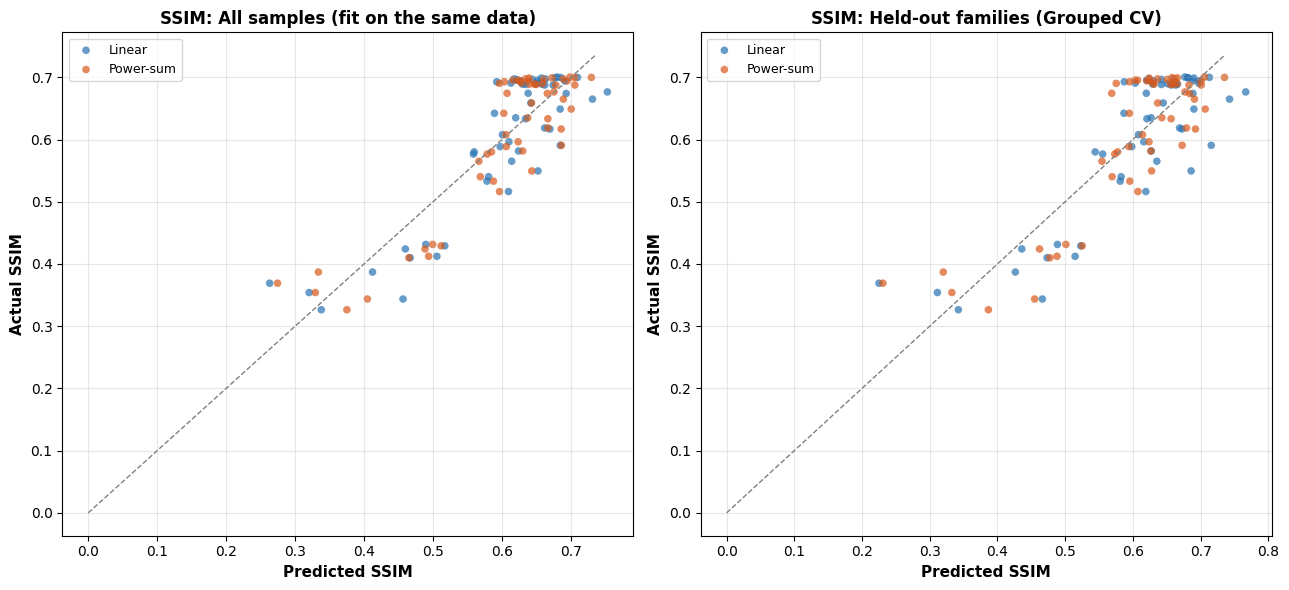


######################################################################
#  Acutance  (n=55 samples with a value, 6 families)
######################################################################

  STAGE 1: all 55 samples, Acutance vs T_dir, Diffuseness Ratio, Opacity (R_b/R_w) together

    Linear (k=4):  R2=0.5628  AIC=-383.90
      Acutance = 0.7603 + -0.008286*T_dir + -0.4722*Diffuseness Ratio + -0.4882*Opacity (R_b/R_w)

    Power-sum (k=6):  R2=0.5977  AIC=-384.46
      Acutance = -0.1235*T_dir^0.423 + -0.3562*Diffuseness Ratio^5.000 + 0.4383*Opacity (R_b/R_w)^-0.277
      Note: exponents of predictors that span a narrow range (diffuseness, opacity) are weakly determined;
      judge the model by the AIC and cross-validation verdicts, not by the individual exponents.

    Delta-AIC (power-sum - linear) = -0.56  ->  no meaningful improvement over multiple linear regression
    'No improvement' means any curvature is too small to detect with this many samples and this much noise;


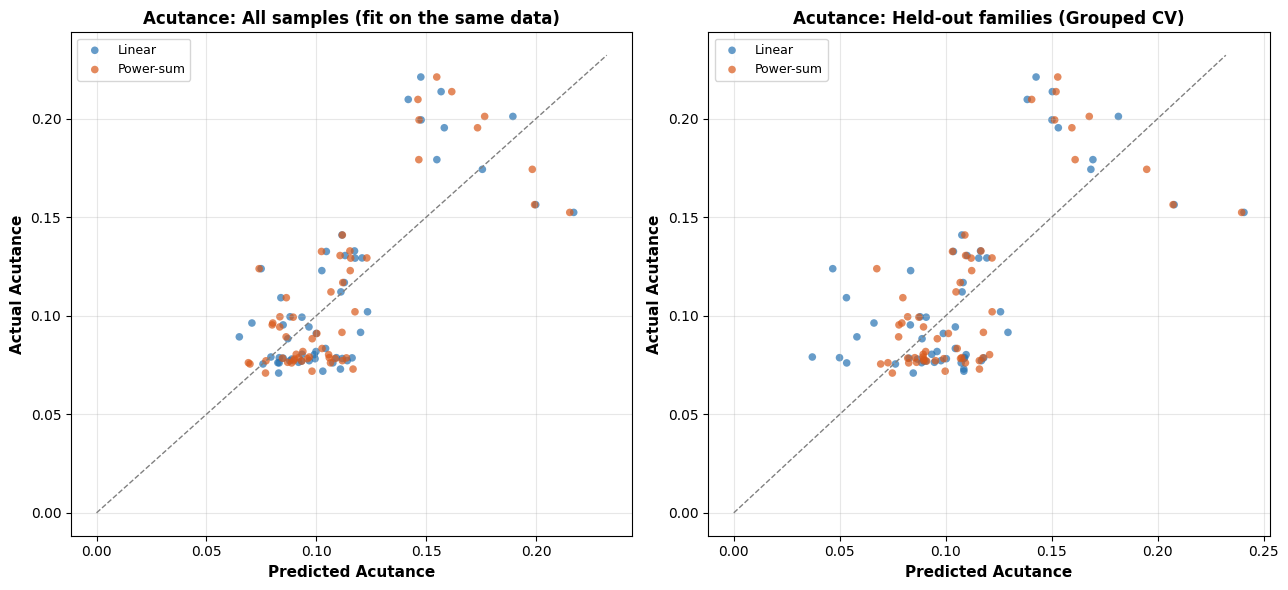


######################################################################
#  Michelson Contrast  (n=55 samples with a value, 6 families)
######################################################################

  STAGE 1: all 55 samples, Michelson Contrast vs T_dir, Diffuseness Ratio, Opacity (R_b/R_w) together

    Linear (k=4):  R2=0.5235  AIC=-318.47
      Michelson Contrast = 1.8 + -0.007758*T_dir + -0.774*Diffuseness Ratio + -0.8045*Opacity (R_b/R_w)

    Power-sum (k=6):  R2=0.5629  AIC=-319.22
      Michelson Contrast = 1.78*T_dir^-0.150 + -0.6149*Diffuseness Ratio^3.032 + -2.805*Opacity (R_b/R_w)^3.218
      Note: exponents of predictors that span a narrow range (diffuseness, opacity) are weakly determined;
      judge the model by the AIC and cross-validation verdicts, not by the individual exponents.

    Delta-AIC (power-sum - linear) = -0.75  ->  no meaningful improvement over multiple linear regression
    'No improvement' means any curvature is too small to detect with this m

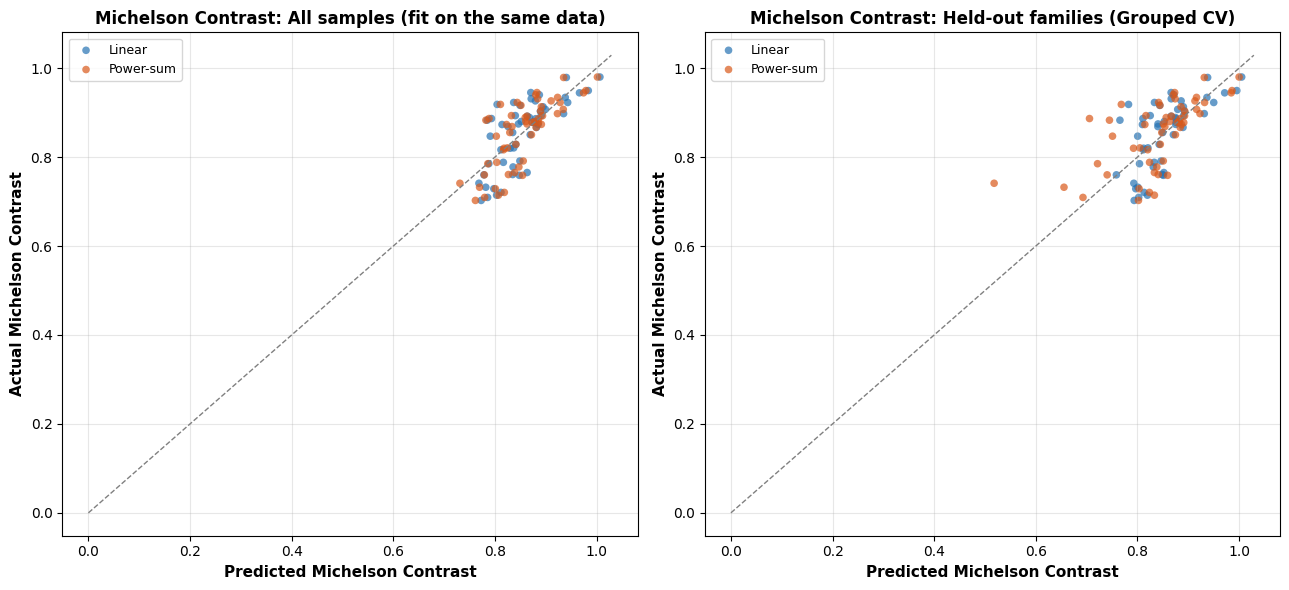


  SUMMARY ACROSS IMAGE METRICS
          Response  n  Linear_R2_all  PowerSum_R2_all  Delta_AIC                                            Stage1_verdict  Linear_CV_R2_grouped  PowerSum_CV_R2_grouped                                                        Stage2_verdict
              SSIM 55          0.765            0.786     -1.353 no meaningful improvement over multiple linear regression                 0.708                   0.720  no meaningful gain over linear (power-sum cuts held-out error by 4%)
          Acutance 55          0.563            0.598     -0.565 no meaningful improvement over multiple linear regression                 0.380                   0.506 power-sum generalizes better than linear (cuts held-out error by 20%)
Michelson Contrast 55          0.523            0.563     -0.754 no meaningful improvement over multiple linear regression                 0.473                   0.203            linear generalizes at least as well as the power-sum model

Saved repor

In [ ]:
"""
Multivariate non-linear model, run separately for each image metric:

    Metric = a * T_dir^a' + b * Diffuseness^b' + c * Opacity^c'

(one equation using all three optical predictors together), compared
against multiple linear regression,

    Metric = c0 + c1*T_dir + c2*Diffuseness + c3*Opacity

for Metric in SSIM, Acutance, Michelson Contrast.

Stage 1: fit both on all samples, compare by AIC.
Stage 2: cross-validation -- leave-one-out (LOO) and leave-one-family-out
         (Grouped). Samples are layered variants of the same base fabric,
         so Grouped holds out a whole base colour at a time.

Fitting method: for fixed exponents (a', b', c') the coefficients (a, b, c)
are linear, so they are solved exactly by least squares and only the three
exponents are searched (many starting points, exponents bounded). Each
predictor is divided by its training-set mean inside the fit so the
exponents are well scaled; coefficients are converted back to original
units for reporting.

CV_R2 = 1 - SSE_model / SSE_baseline, baseline = training-fold mean.
> 0 beats ignoring the predictors; < 0 is worse than ignoring them.

Each metric uses only the samples that have a value for it, so a sample
with no matched image only drops out of the image metrics it lacks.

Per-sample predictions are saved to the report, one sheet per metric
("Pred_<metric>"): Actual, all-data fit, held-out families (Grouped CV)
and leave-one-out, for both models.

Reads fabric_analysis_report.xlsx ("Per-Sample Values").
"""

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

warnings.filterwarnings('ignore', category=RuntimeWarning)

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"
SHEET_NAME  = "Per-Sample Values"

OUTPUT_DIR = "/content/drive/MyDrive/Master/All data report/Non-linear correlation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RESPONSES = [                    # (column in report, display name)
    ('SSIM',               'SSIM'),
    ('Acutance',           'Acutance'),
    ('Michelson_Contrast', 'Michelson Contrast'),
]
PREDICTORS = [
    ('weighted_T_dir', 'T_dir'),
    ('diffuseness',    'Diffuseness Ratio'),
    ('opacity',        'Opacity (R_b/R_w)'),
]

EXPONENT_BOUNDS = (-5.0, 5.0)   # exponents a', b', c' are searched inside this range
N_RANDOM_STARTS = 20            # extra random starting points for the exponent search
RANDOM_SEED = 0

# Non-linear model counts as generalizing better only if grouped CV_R2 > 0
# AND it cuts linear's held-out squared error by at least this fraction.
CV_MIN_ERROR_REDUCTION = 0.20

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)

pred_cols = [c for c, _ in PREDICTORS]
pred_names = [d for _, d in PREDICTORS]

if (df[pred_cols].dropna() <= 0).any().any():
    raise ValueError("Power terms need every predictor value > 0, but some are <= 0. "
                     "Check weighted_T_dir / diffuseness / opacity in the report.")

print(f"Loaded {len(df)} samples")

# ---------------------------------------------------------------
# FAMILIES (for grouped cross-validation)
# ---------------------------------------------------------------
def family_of(label):
    """'blue + 2 black on white' -> 'blue'; 'red' -> 'red'; two-colour mixes
    starting with a count ('2 red + 4 white') -> 'mixed'."""
    t = re.sub(r'\s+on white$', '', str(label).strip(), flags=re.IGNORECASE)
    t = re.sub(r'\s+nonwoven$', '', t, flags=re.IGNORECASE).lower()
    if re.match(r'^\d', t):
        return 'mixed'
    tokens = t.split()
    return tokens[0] if tokens else 'unknown'


df['Family'] = df['Sample'].map(family_of)
print("\nFabric families used for grouping (check these):")
print(df['Family'].value_counts().to_string())

# ---------------------------------------------------------------
# MODELS
# ---------------------------------------------------------------
def fit_linear(Xt, yt):
    A = np.column_stack([np.ones(len(Xt)), Xt])
    coef, *_ = np.linalg.lstsq(A, yt, rcond=None)
    return {
        'k': 4,
        'coef': coef,
        'predict': lambda Xn: np.column_stack([np.ones(len(Xn)), Xn]) @ coef,
    }


def fit_power_sum(Xt, yt):
    m = Xt.mean(axis=0)
    Xs = Xt / m
    lo, hi = EXPONENT_BOUNDS

    def design(e, Z):
        return np.column_stack([Z[:, i] ** e[i] for i in range(Z.shape[1])])

    def solve(e):
        Phi = design(e, Xs)
        c, *_ = np.linalg.lstsq(Phi, yt, rcond=None)
        return c, Phi

    def resid(e):
        c, Phi = solve(e)
        return yt - Phi @ c

    rng = np.random.default_rng(RANDOM_SEED)
    starts = [np.ones(Xt.shape[1])] + [rng.uniform(-3, 3, Xt.shape[1]) for _ in range(N_RANDOM_STARTS)]

    best = None
    for e0 in starts:
        try:
            r = least_squares(resid, np.clip(e0, lo, hi), bounds=(lo, hi))
        except (ValueError, FloatingPointError):
            continue
        if not np.isfinite(r.cost):
            continue
        if best is None or r.cost < best.cost:
            best = r
    if best is None:
        return None

    e = best.x
    c, _ = solve(e)
    return {
        'k': 6,
        'exponents': e,
        'coef': c / m ** e,                      # coefficients in ORIGINAL units
        'at_bound': bool(np.any((np.abs(e - lo) < 1e-3) | (np.abs(e - hi) < 1e-3))),
        'predict': lambda Xn: design(e, Xn / m) @ c,
    }


MODELS = [('Linear', fit_linear), ('Power-sum', fit_power_sum)]


def aic(n_obs, k, ss_res):
    return n_obs * np.log(max(ss_res, 1e-12) / n_obs) + 2 * k


def r2_score(yt, pred):
    return 1 - np.sum((yt - pred) ** 2) / np.sum((yt - yt.mean()) ** 2)


def cv_run(fit_fn, folds, X, y):
    n = len(y)
    pred = np.full(n, np.nan)
    base = np.full(n, np.nan)
    n_failed = 0
    for test_idx in folds:
        train = np.ones(n, dtype=bool)
        train[test_idx] = False
        base[test_idx] = y[train].mean()
        fit = fit_fn(X[train], y[train])
        if fit is None:
            n_failed += 1
            continue
        p = fit['predict'](X[test_idx])
        if not np.all(np.isfinite(p)):
            n_failed += 1
            continue
        pred[test_idx] = p
    if not np.all(np.isfinite(pred)):
        return pred, np.nan, n_failed
    return pred, 1 - np.sum((y - pred) ** 2) / np.sum((y - base) ** 2), n_failed


def cv_verdict(r2_lin, r2_pow):
    if not np.isfinite(r2_pow):
        return "power-sum model failed in cross-validation", np.nan
    if not np.isfinite(r2_lin):
        return "linear baseline failed in cross-validation", np.nan
    if max(r2_lin, r2_pow) <= 0:
        return "no predictive skill on held-out families (nothing beats the mean)", np.nan
    if r2_pow <= r2_lin:
        return "linear generalizes at least as well as the power-sum model", 0.0
    reduction = 1 - (1 - r2_pow) / (1 - r2_lin)   # = 1 - SSE_power / SSE_linear
    if reduction >= CV_MIN_ERROR_REDUCTION:
        return f"power-sum generalizes better than linear (cuts held-out error by {reduction:.0%})", reduction
    return f"no meaningful gain over linear (power-sum cuts held-out error by {reduction:.0%})", reduction


# ---------------------------------------------------------------
# ANALYSIS FOR ONE IMAGE METRIC
# ---------------------------------------------------------------
def analyze(resp_col, resp_name):
    sub = df[['Sample', 'Family', resp_col] + pred_cols].dropna().reset_index(drop=True)
    X = sub[pred_cols].to_numpy(dtype=float)
    y = sub[resp_col].to_numpy(dtype=float)
    families = sub['Family'].to_numpy()
    n = len(y)

    print("\n" + "#" * 70)
    print(f"#  {resp_name}  (n={n} samples with a value, {len(np.unique(families))} families)")
    print("#" * 70)

    # ---- Stage 1: all samples ----
    print(f"\n  STAGE 1: all {n} samples, {resp_name} vs {', '.join(pred_names)} together")
    fits_all, stage1_rows = {}, []
    for name, fit_fn in MODELS:
        fit = fit_fn(X, y)
        if fit is None:
            print(f"    {name}: fit failed")
            continue
        pred = fit['predict'](X)
        ss = np.sum((y - pred) ** 2)
        fit['r2'], fit['aic'] = r2_score(y, pred), aic(n, fit['k'], ss)
        fits_all[name] = fit

        if name == 'Linear':
            c0, c1, c2, c3 = fit['coef']
            formula = (f"{resp_name} = {c0:.4g} + {c1:.4g}*{pred_names[0]} "
                       f"+ {c2:.4g}*{pred_names[1]} + {c3:.4g}*{pred_names[2]}")
        else:
            a, e = fit['coef'], fit['exponents']
            formula = (f"{resp_name} = {a[0]:.4g}*{pred_names[0]}^{e[0]:.3f} "
                       f"+ {a[1]:.4g}*{pred_names[1]}^{e[1]:.3f} "
                       f"+ {a[2]:.4g}*{pred_names[2]}^{e[2]:.3f}")
        print(f"\n    {name} (k={fit['k']}):  R2={fit['r2']:.4f}  AIC={fit['aic']:.2f}")
        print(f"      {formula}")
        if name == 'Power-sum':
            print("      Note: exponents of predictors that span a narrow range (diffuseness, opacity) "
                  "are weakly determined;\n      judge the model by the AIC and cross-validation "
                  "verdicts, not by the individual exponents.")
        if fit.get('at_bound'):
            print(f"      WARNING: an exponent sits at the search bound {EXPONENT_BOUNDS} -- "
                  f"it is not well determined by this data.")
        stage1_rows.append({'Response': resp_name, 'Model': name, 'k': fit['k'],
                            'R2': fit['r2'], 'AIC': fit['aic'], 'Formula': formula})

    stage1_verdict, d_aic = "", np.nan
    if 'Linear' in fits_all and 'Power-sum' in fits_all:
        d_aic = fits_all['Power-sum']['aic'] - fits_all['Linear']['aic']
        if d_aic < -10:
            stage1_verdict = "STRONG evidence the power-sum form fits better than linear"
        elif d_aic < -2:
            stage1_verdict = "weak hint only, likely chance"
        else:
            stage1_verdict = "no meaningful improvement over multiple linear regression"
        print(f"\n    Delta-AIC (power-sum - linear) = {d_aic:+.2f}  ->  {stage1_verdict}")
        if d_aic >= -2:
            print("    'No improvement' means any curvature is too small to detect with this many "
                  "samples and this much noise;\n    it does not prove the relationship is linear.")
        print("    (Samples are not independent, so stage 1 alone can be over-confident; see stage 2.)")

    # ---- Stage 2: cross-validation ----
    schemes = {
        'LOO': [np.array([i]) for i in range(n)],
        'Grouped': [np.where(families == f)[0] for f in np.unique(families)],
    }
    print(f"\n  STAGE 2: cross-validation")
    print(f"    {'Model':<12} {'LOO CV_R2':>10} {'Grouped CV_R2':>14}")

    cv_rows, oof = [], {}
    for name, fit_fn in MODELS:
        row = {'Response': resp_name, 'Model': name}
        for scheme, folds in schemes.items():
            pred, r2, n_failed = cv_run(fit_fn, folds, X, y)
            row[f'CV_R2_{scheme}'] = r2
            row[f'Failed_folds_{scheme}'] = n_failed
            oof[(name, scheme)] = pred
        cv_rows.append(row)
        fmt = lambda v: f"{v:10.3f}" if np.isfinite(v) else "    failed"
        print(f"    {name:<12} {fmt(row['CV_R2_LOO'])} {fmt(row['CV_R2_Grouped']):>14}")

    r2_lin = next(r['CV_R2_Grouped'] for r in cv_rows if r['Model'] == 'Linear')
    r2_pow = next(r['CV_R2_Grouped'] for r in cv_rows if r['Model'] == 'Power-sum')
    stage2_verdict, reduction = cv_verdict(r2_lin, r2_pow)
    print(f"\n    Stage 2 verdict (held-out families): {stage2_verdict}")

    # ---- Per-sample predictions (for comparing with other results) ----
    pred_df = sub[['Sample', 'Family']].copy()
    pred_df['Actual'] = y
    for m, _ in MODELS:
        tag = m.replace('-', '')
        pred_df[f'{tag}_all_data'] = fits_all[m]['predict'](X) if m in fits_all else np.nan
        pred_df[f'{tag}_grouped_cv'] = oof[(m, 'Grouped')]
        pred_df[f'{tag}_loo_cv'] = oof[(m, 'LOO')]

    # ---- Plot: predicted vs actual ----
    colors = {'Linear': (0.15, 0.45, 0.70), 'Power-sum': (0.85, 0.35, 0.10)}
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    panels = [
        ("All samples (fit on the same data)", {m: fits_all[m]['predict'](X) for m in fits_all}),
        ("Held-out families (Grouped CV)", {m: oof[(m, 'Grouped')] for m, _ in MODELS}),
    ]
    lo_l, hi_l = min(y.min(), 0), y.max() * 1.05
    for ax, (title, preds) in zip(axes, panels):
        ax.plot([lo_l, hi_l], [lo_l, hi_l], color='gray', linestyle='--', linewidth=1)
        for m, p in preds.items():
            ax.scatter(p, y, s=30, alpha=0.7, color=colors[m], edgecolor='none', label=m)
        ax.set_xlabel(f"Predicted {resp_name}", fontsize=11, fontweight='bold')
        ax.set_ylabel(f"Actual {resp_name}", fontsize=11, fontweight='bold')
        ax.set_title(f"{resp_name}: {title}", fontsize=12, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = re.sub(r'[^\w\-]+', '_', resp_name)
    plot_path = os.path.join(OUTPUT_DIR, f"multivariate_{safe}.png")
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    print(f"\n  Saved plot to {plot_path}")
    plt.show()

    summary = {
        'Response': resp_name, 'n': n,
        'Linear_R2_all': fits_all['Linear']['r2'] if 'Linear' in fits_all else np.nan,
        'PowerSum_R2_all': fits_all['Power-sum']['r2'] if 'Power-sum' in fits_all else np.nan,
        'Delta_AIC': d_aic, 'Stage1_verdict': stage1_verdict,
        'Linear_CV_R2_grouped': r2_lin, 'PowerSum_CV_R2_grouped': r2_pow,
        'Stage2_verdict': stage2_verdict,
    }
    return summary, stage1_rows, cv_rows, pred_df


# ---------------------------------------------------------------
# RUN FOR EVERY IMAGE METRIC
# ---------------------------------------------------------------
summary_rows, all_stage1, all_cv, all_preds = [], [], [], {}
for resp_col, resp_name in RESPONSES:
    summary, s1, cv, pred_df = analyze(resp_col, resp_name)
    summary_rows.append(summary)
    all_stage1 += s1
    all_cv += cv
    all_preds[resp_name] = pred_df

summary_df = pd.DataFrame(summary_rows)
print("\n" + "=" * 70)
print("  SUMMARY ACROSS IMAGE METRICS")
print("=" * 70)
print(summary_df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

report_path = os.path.join(OUTPUT_DIR, "multivariate_report.xlsx")
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    summary_df.to_excel(writer, sheet_name="Summary", index=False)
    pd.DataFrame(all_stage1).to_excel(writer, sheet_name="All-data fit", index=False)
    pd.DataFrame(all_cv).to_excel(writer, sheet_name="CV results", index=False)
    df[['Sample', 'Family']].to_excel(writer, sheet_name="Family groups", index=False)
    for resp_name, pdf in all_preds.items():
        sheet = ("Pred_" + re.sub(r'[^\w\-]+', '_', resp_name))[:31]
        pdf.to_excel(writer, sheet_name=sheet, index=False)
print(f"\nSaved report to {report_path}")

### Fit power-sum models with SciPy (Gemini)

Use `curve_fit` to fit SSIM, acutance, and Michelson contrast on the full dataset.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. CONFIGURATION
# ==========================================
excel_path = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"   # Replace with your Excel file path
sheet_name = "Per-Sample Values"     # Replace with your sheet name
output_dir = "/content/drive/MyDrive/Master/All data report/Gemini"  # Directory for saving outputs


os.makedirs(output_dir, exist_ok=True)

# ==========================================
# 2. LOAD DATA FROM EXCEL
# ==========================================
df = pd.read_excel(excel_path, sheet_name=sheet_name)
print(f"Loaded sheet '{sheet_name}' with {len(df)} samples.")

# Independent features (inputs)
td = df['weighted_T_dir'].values
diff = df['diffuseness'].values
opac = df['opacity'].values
X_data = np.array([td, diff, opac])

# ==========================================
# 3. DEFINE NON-LINEAR MODEL
# ==========================================
def non_linear_model(X, a, a_prime, b, b_prime, c, c_prime):
    t, d, o = X
    term1 = a * (np.maximum(t, 1e-6) ** a_prime)
    term2 = b * (np.maximum(d, 1e-6) ** b_prime)
    term3 = c * (np.maximum(o, 1e-6) ** c_prime)
    return term1 + term2 + term3

# ==========================================
# 4. ITERATE THROUGH TARGET PARAMETERS
# ==========================================
targets = ['SSIM', 'Michelson_Contrast', 'Acutance']
initial_guesses = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

summary_records = []  # List to store summary data for the second sheet

for target in targets:
    if target not in df.columns:
        print(f"\n[Warning] Column '{target}' not found in the Excel sheet. Skipping.")
        continue

    print(f"\n----------------------------------------")
    print(f"Processing Target: {target}")
    print(f"----------------------------------------")

    y_actual = df[target].values

    try:
        # Fit the curve for the current target
        popt, _ = curve_fit(non_linear_model, X_data, y_actual, p0=initial_guesses, maxfev=10000)
        a_opt, a_prime_opt, b_opt, b_prime_opt, c_opt, c_prime_opt = popt

        print(f"Optimized Parameters:")
        print(f"  a = {a_opt:.4f}, a' = {a_prime_opt:.4f}")
        print(f"  b = {b_opt:.4f}, b' = {b_prime_opt:.4f}")
        print(f"  c = {c_opt:.4f}, c' = {c_prime_opt:.4f}")

    except Exception as e:
        print(f"Curve fitting failed for {target}: {e}")
        continue

    # Calculate predictions and residuals
    y_pred = non_linear_model(X_data, *popt)
    df[f'{target}_Predicted'] = y_pred
    df[f'{target}_Residual'] = y_actual - y_pred

    # Statistical performance metrics
    ss_res = np.sum((y_actual - y_pred) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    r_squared = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean((y_actual - y_pred) ** 2))

    print(f"Performance -> R^2: {r_squared:.4f} | RMSE: {rmse:.4f}")

    # Outlier flagging (using 2 standard deviations of the residuals)
    res_mean = df[f'{target}_Residual'].mean()
    res_std = df[f'{target}_Residual'].std()
    df[f'{target}_Is_Outlier'] = np.abs(df[f'{target}_Residual'] - res_mean) > (2 * res_std)

    # Format equation string with the optimized numbers
    equation_string = (
        f"{target} = {a_opt:.4f} * (T_direct)^{a_prime_opt:.4f} + "
        f"{b_opt:.4f} * (diffuseness)^{b_prime_opt:.4f} + "
        f"{c_opt:.4f} * (opacity)^{c_prime_opt:.4f}"
    )

    # Append to summary record
    summary_records.append({
        'Target_Parameter': target,
        'Fitted_Equation': equation_string,
        'R_Squared': r_squared,
        'RMSE': rmse,
        'a': a_opt,
        'a_prime': a_prime_opt,
        'b': b_opt,
        'b_prime': b_prime_opt,
        'c': c_opt,
        'c_prime': c_prime_opt
    })

    # Generate and save plot for this target
    plt.figure(figsize=(7, 5))
    plt.scatter(y_pred, y_actual, c=df[f'{target}_Is_Outlier'], cmap='coolwarm', edgecolor='k', alpha=0.8)
    plt.axline((min(y_actual), min(y_actual)), slope=1, color='gray', linestyle='--', label='Ideal Fit (y=x)')
    plt.xlabel(f'Predicted {target}')
    plt.ylabel(f'Actual {target}')
    plt.title(f'{target}: Actual vs Predicted (R^2 = {r_squared:.3f})')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()

    plot_filename = os.path.join(output_dir, f'actual_vs_predicted_{target.lower()}.png')
    plt.savefig(plot_filename, dpi=300)
    plt.close()

# ==========================================
# 5. SAVE MULTI-SHEET EXCEL REPORT
# ==========================================
summary_df = pd.DataFrame(summary_records)
output_excel_path = os.path.join(output_dir, 'all_targets_optimization_results.xlsx')

# Using ExcelWriter to save both sheets into one workbook
with pd.ExcelWriter(output_excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Detailed_Results', index=False)
    summary_df.to_excel(writer, sheet_name='Model_Summary', index=False)

print(f"\nMulti-sheet Excel report saved to: {output_excel_path}")
print(f"- Sheet 1 ('Detailed_Results'): Sample-by-sample data, predictions, and outliers.")
print(f"- Sheet 2 ('Model_Summary'): Final equations, coefficients, R^2, and RMSE.")
print(f"Plots saved in directory: {output_dir}")

Loaded sheet 'Per-Sample Values' with 55 samples.

----------------------------------------
Processing Target: SSIM
----------------------------------------
Optimized Parameters:
  a = 0.0103, a' = 1.1369
  b = 0.8806, b' = 4.7953
  c = 2.2288, c' = 2.6172
Performance -> R^2: 0.6359 | RMSE: 0.0684

----------------------------------------
Processing Target: Michelson_Contrast
----------------------------------------
Optimized Parameters:
  a = -471.8997, a' = 0.0003
  b = 216.4380, b' = -0.0023
  c = 256.3162, c' = -0.0009
Performance -> R^2: 0.4825 | RMSE: 0.0536

----------------------------------------
Processing Target: Acutance
----------------------------------------
Optimized Parameters:
  a = -0.0179, a' = 0.8233
  b = 200.3767, b' = -0.0016
  c = -200.3544, c' = 0.0008
Performance -> R^2: 0.5746 | RMSE: 0.0280

Multi-sheet Excel report saved to: /content/drive/MyDrive/Master/All data report/Gemini/all_targets_optimization_results.xlsx
- Sheet 1 ('Detailed_Results'): Sample-by-

### Random train/test splits with a linear baseline (Claude)

Compare linear and power-sum models with a held-out test set and repeated random splits.

Loaded 55 samples

SSIM: 45 train / 10 test
  Test samples: 3 green + 3 white on white, red + 2 black on white, blue , blue + 2 white on white, white + 1 red on white, 2 green + 4 white on white, 3 red + 3 white on white, blue + 1 black on white, brown + 1 black on white, white + 2 red on white
  Power-sum + intercept  train R2=0.775  test R2=0.836 (own-set 0.825)  RMSE train=0.0517 test=0.0533
      optimiser check: agree  (grid+TRF [0.282 3.304 0.951]  vs  DE [0.282 3.305 0.951]; exponents at bound: 0)
  Power-sum              train R2=0.770  test R2=0.808 (own-set 0.796)  RMSE train=0.0523 test=0.0576
      optimiser check: agree  (grid+TRF [ 0.359  3.729 -0.29 ]  vs  DE [ 0.359  3.729 -0.29 ]; exponents at bound: 0)
  Linear                 train R2=0.752  test R2=0.781 (own-set 0.767)  RMSE train=0.0543 test=0.0616

Acutance: 45 train / 10 test
  Test samples: 3 green + 3 white on white, red + 2 black on white, blue , blue + 2 white on white, white + 1 red on white, 2 green + 4 wh

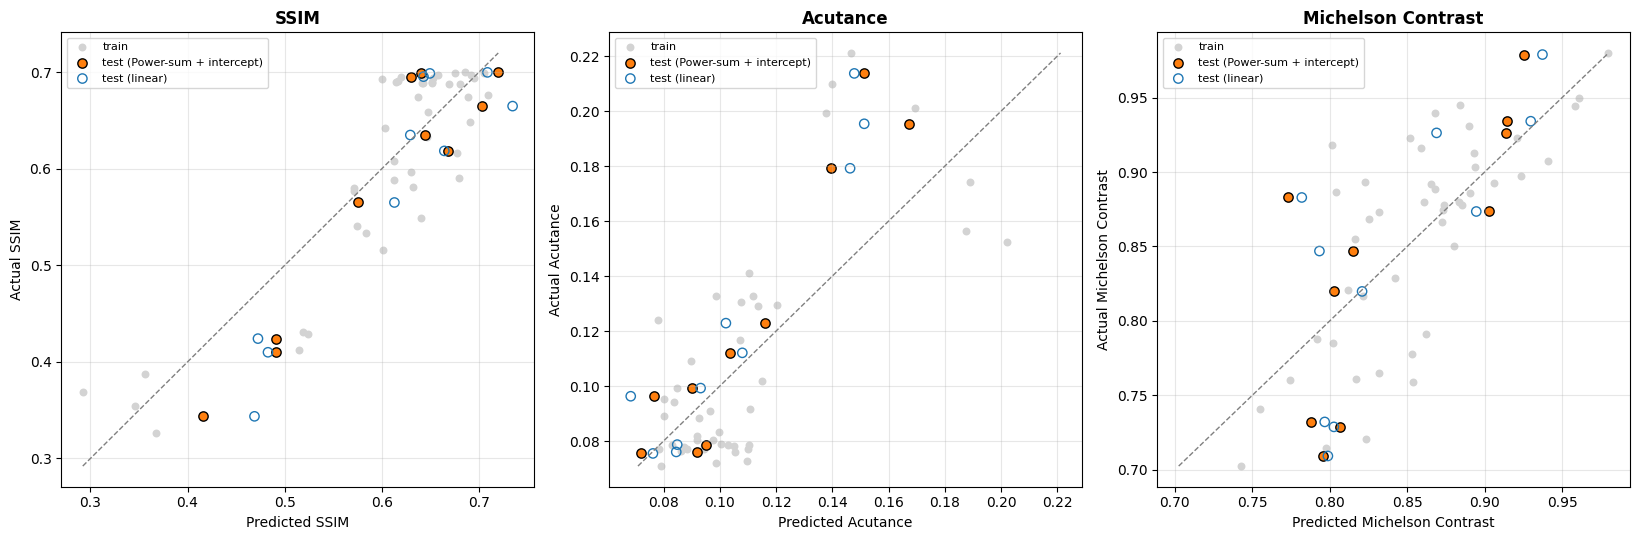

Saved /content/drive/MyDrive/Master/All data report/Train test/train_test_plot.png


In [6]:
"""
Random train/test split: fit on the training samples, test on N_TEST held-out samples.

Models (same three predictors):
    Power-sum + intercept : Metric = c0 + a*T_dir^a' + b*Diffuseness^b' + c*Opacity^c'
    Power-sum             : Metric =      a*T_dir^a' + b*Diffuseness^b' + c*Opacity^c'
    Linear                : Metric = c0 + c1*T_dir + c2*Diffuseness + c3*Opacity

OPTIMISER for the power-sum models (only the 3 exponents are searched; for any exponents the
coefficients/intercept are solved exactly by least squares):
    1. GRID SEARCH over every exponent combination in EXPONENT_BOUNDS (step GRID_STEP).
    2. TRF polish (scipy least_squares) from the best, well-separated grid points, the
       all-ones start (linear-like model) and N_RANDOM_STARTS random starts; best result kept.
    3. CROSS-CHECK: differential evolution (a global optimiser) is run on the same training
       data; its error and exponents are compared with the TRF result for every fit, and if DE
       finds a LOWER error its solution is the one used.
       Note: 'agree' only shows that two searches reached the same answer, not that no better
       answer exists.

Verdict per fit:
    agree                                    same error, same exponents
    same error, different exponents          flat valley: data cannot pin the exponents
    DE found lower error                     grid+TRF may be stuck in a local minimum
    grid+TRF lower than DE                   DE did not converge; grid+TRF is trusted

R2 is reported two ways for BOTH train and test:
    R2                 : baseline = mean of the TRAINING samples
    R2 (own-set mean)  : baseline = mean of the samples being scored (sklearn convention)
Error = Actual - Predicted. 'Mean error' is signed (bias); STD uses n-1.
Caveat: layered variants of one fabric land on both sides of a random split, so test scores
are optimistic compared with leave-one-family-out results.

Reads all_report.xlsx ("Per-Sample Values"). Writes train_test_report.xlsx.
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, differential_evolution

warnings.filterwarnings('ignore', category=RuntimeWarning)

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
REPORT_FILE = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"
SHEET_NAME  = "Per-Sample Values"
OUTPUT_DIR  = "/content/drive/MyDrive/Master/All data report/Train test"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RESPONSES = [('SSIM', 'SSIM'), ('Acutance', 'Acutance'),
             ('Michelson_Contrast', 'Michelson Contrast')]
PREDICTORS = [('weighted_T_dir', 'T_dir'), ('diffuseness', 'Diffuseness Ratio'),
              ('opacity', 'Opacity (R_b/R_w)')]

N_TEST       = 10        # samples held out (the rest are used for training)
SPLIT_SEED   = 42        # change to get a different random split
N_REPEATS    = 10      # extra random splits for the stability check (0 = skip)
RANDOM_SEED  = 0
MAIN_MODEL   = 'Power-sum + intercept'   # the model drawn in the plot

# --- optimiser settings ---
EXPONENT_BOUNDS  = (-5.0, 5.0)
GRID_STEP        = 0.5     # 0.5 -> 21 values per exponent (9,261 combinations); 0.25 -> 68,921 (slower)
N_GRID_STARTS    = 5       # best well-separated grid points polished with TRF
START_SEPARATION = 1.0     # grid starts must differ by at least this in some exponent
N_RANDOM_STARTS  = 20      # extra random starting points polished with TRF (as in the earlier version)
CROSSCHECK       = True    # differential-evolution cross-check
DE_IN_REPEATS    = True    # also cross-check inside the repeated splits (slower)
SSE_TOL          = 1e-3    # errors within 0.1% count as "the same error"
EXP_TOL          = 0.25    # exponents within this count as "the same exponents"

# ---------------------------------------------------------------
# DATA
# ---------------------------------------------------------------
df = pd.read_excel(REPORT_FILE, sheet_name=SHEET_NAME)
pred_cols = [c for c, _ in PREDICTORS]
pred_names = [d for _, d in PREDICTORS]
if (df[pred_cols].dropna() <= 0).any().any():
    raise ValueError("Power terms need every predictor value > 0. Check the report.")
print(f"Loaded {len(df)} samples")

# ---------------------------------------------------------------
# MODELS
# ---------------------------------------------------------------
def fit_linear(Xt, yt, crosscheck=False):
    A = np.column_stack([np.ones(len(Xt)), Xt])
    coef, *_ = np.linalg.lstsq(A, yt, rcond=None)
    return {'intercept': coef[0], 'coef': coef[1:], 'exponents': None,
            'predict': lambda Xn: np.column_stack([np.ones(len(Xn)), Xn]) @ coef}


def fit_power_sum(Xt, yt, intercept=False, crosscheck=False):
    m = Xt.mean(axis=0)
    Xs = Xt / m
    lo, hi = EXPONENT_BOUNDS
    n = len(yt)

    def design(e, Z):
        cols = [Z[:, i] ** e[i] for i in range(Z.shape[1])]
        if intercept:
            cols = [np.ones(len(Z))] + cols
        return np.column_stack(cols)

    def solve(e):
        Phi = design(e, Xs)
        c, *_ = np.linalg.lstsq(Phi, yt, rcond=None)
        return c, Phi

    def resid(e):
        c, Phi = solve(e)
        return yt - Phi @ c

    def sse(e):
        r = resid(np.asarray(e))
        return float(r @ r)

    # ---- 1) grid search over all exponent combinations ----
    grid = np.arange(lo, hi + 1e-9, GRID_STEP)
    G = len(grid)
    pw = [np.stack([Xs[:, i] ** g for g in grid], axis=1) for i in range(3)]   # (n, G) per predictor
    ones = np.ones(n)
    sse_grid = np.full((G, G, G), np.inf)
    for i0 in range(G):
        for i1 in range(G):
            for i2 in range(G):
                cols = [pw[0][:, i0], pw[1][:, i1], pw[2][:, i2]]
                if intercept:
                    cols = [ones] + cols
                Phi = np.column_stack(cols)
                c, *_ = np.linalg.lstsq(Phi, yt, rcond=None)
                r = yt - Phi @ c
                v = float(r @ r)
                if np.isfinite(v):
                    sse_grid[i0, i1, i2] = v

    starts = []
    for flat in np.argsort(sse_grid, axis=None):
        if not np.isfinite(sse_grid.flat[flat]):
            break
        e0 = grid[list(np.unravel_index(flat, sse_grid.shape))]
        if all(np.max(np.abs(e0 - s)) >= START_SEPARATION for s in starts):
            starts.append(e0)
        if len(starts) >= N_GRID_STARTS:
            break
    starts.append(np.ones(3))          # all exponents = 1 (the linear-like model)
    rng = np.random.default_rng(RANDOM_SEED)
    starts += [rng.uniform(-3, 3, 3) for _ in range(N_RANDOM_STARTS)]

    # ---- 2) TRF polish ----
    best = None
    for e0 in starts:
        try:
            r = least_squares(resid, np.clip(e0, lo, hi), bounds=(lo, hi))
        except (ValueError, FloatingPointError):
            continue
        if np.isfinite(r.cost) and (best is None or r.cost < best.cost):
            best = r
    if best is None:
        return None
    e = best.x
    trf_exps, trf_sse = e.copy(), sse(e)
    out_check, final_from = None, 'TRF'

    # ---- 3) differential-evolution cross-check (its answer is used if it is lower) ----
    if crosscheck:
        de = differential_evolution(sse, [(lo, hi)] * 3, seed=RANDOM_SEED, tol=1e-8,
                                    maxiter=300, popsize=15, polish=True)
        out_check = {'grid_trf_sse': trf_sse, 'de_sse': float(de.fun),
                     'trf_exponents': trf_exps, 'de_exponents': de.x}
        if de.fun < trf_sse * (1 - 1e-9):
            e, final_from = np.clip(de.x, lo, hi), 'DE'

    c, _ = solve(e)
    c_terms = c[1:] if intercept else c
    out = {'intercept': c[0] if intercept else None,
           'coef': c_terms / m ** e,
           'exponents': e,
           'final_from': final_from,
           'n_at_bound': int(np.sum((np.abs(e - lo) < 1e-3) | (np.abs(e - hi) < 1e-3))),
           'predict': lambda Xn: design(e, Xn / m) @ c}
    if out_check:
        out['check'] = out_check
    return out


MODELS = [('Power-sum + intercept', lambda X, y, cc=False: fit_power_sum(X, y, True, cc)),
          ('Power-sum',             lambda X, y, cc=False: fit_power_sum(X, y, False, cc)),
          ('Linear',                fit_linear)]


def check_row(resp, mname, split, fit):
    ck = fit.get('check')
    if ck is None:
        return None
    e, ed = ck['trf_exponents'], ck['de_exponents']
    rel = (ck['grid_trf_sse'] - ck['de_sse']) / max(ck['grid_trf_sse'], 1e-12)   # > 0: DE lower
    maxd = float(np.max(np.abs(e - ed)))
    if rel > SSE_TOL:
        verdict = "DE found lower error (grid+TRF may be stuck)"
    elif rel < -SSE_TOL:
        verdict = "grid+TRF lower than DE (DE did not converge)"
    elif maxd > EXP_TOL:
        verdict = "same error, different exponents (flat valley)"
    else:
        verdict = "agree"
    return {'Response': resp, 'Model': mname, 'Split': split,
            'SSE grid+TRF': ck['grid_trf_sse'], 'SSE DE': ck['de_sse'],
            'Rel. SSE gap (DE lower > 0)': rel, 'Max exponent diff': maxd,
            'Exponents at bound (grid+TRF)': fit['n_at_bound'],
            'Exponents grid+TRF': str(np.round(e, 3)), 'Exponents DE': str(np.round(ed, 3)),
            'Verdict': verdict}


def formula_of(resp, mname, fit):
    c0 = "" if fit['intercept'] is None else f"{fit['intercept']:.4g} + "
    if mname == 'Linear':
        terms = " + ".join(f"{fit['coef'][i]:.4g}*{pred_names[i]}" for i in range(3))
    else:
        terms = " + ".join(f"{fit['coef'][i]:.4g}*{pred_names[i]}^{fit['exponents'][i]:.3f}" for i in range(3))
    return f"{resp} = {c0}{terms}"


METRIC_KEYS = ['R2', 'R2 (own-set mean)', 'Max abs error', 'STD of error', 'Mean error', 'Mean abs error', 'RMSE']


def metrics(y, p, train_mean):
    err = y - p
    sse = np.sum(err ** 2)
    return {'n': len(y),
            'R2': 1 - sse / np.sum((y - train_mean) ** 2),
            'R2 (own-set mean)': 1 - sse / np.sum((y - y.mean()) ** 2),
            'Max abs error': np.max(np.abs(err)),
            'STD of error': np.std(err, ddof=1) if len(err) > 1 else np.nan,
            'Mean error': np.mean(err),
            'Mean abs error': np.mean(np.abs(err)),
            'RMSE': np.sqrt(np.mean(err ** 2))}


def split_idx(n, rng):
    test = rng.choice(n, size=N_TEST, replace=False)
    train = np.setdiff1d(np.arange(n), test)
    return train, test


# ---------------------------------------------------------------
# 1) SINGLE SPLIT
# ---------------------------------------------------------------
metric_rows, pred_frames, param_rows, plot_data, check_single = [], [], [], {}, []
for col, name in RESPONSES:
    sub = df[['Sample'] + [col] + pred_cols].dropna().reset_index(drop=True)
    X = sub[pred_cols].to_numpy(float)
    y = sub[col].to_numpy(float)
    train, test = split_idx(len(y), np.random.default_rng(SPLIT_SEED))
    print(f"\n{name}: {len(train)} train / {len(test)} test")
    print("  Test samples:", ", ".join(sub['Sample'][test].astype(str)))

    frame = pd.DataFrame({'Response': name, 'Sample': sub['Sample'], 'Set': 'train', 'Actual': y})
    frame.loc[test, 'Set'] = 'test'
    base = y[train].mean()

    for mname, fit_fn in MODELS:
        fit = fit_fn(X[train], y[train], CROSSCHECK) if mname != 'Linear' else fit_fn(X[train], y[train])
        if fit is None:
            print(f"  {mname}: fit failed")
            continue
        p = fit['predict'](X)
        frame[f'Pred_{mname}'] = p
        frame[f'Error_{mname}'] = y - p
        res = {}
        for setname, idx in [('train', train), ('test', test)]:
            row = {'Response': name, 'Model': mname, 'Set': setname}
            row.update(metrics(y[idx], p[idx], base))
            metric_rows.append(row)
            res[setname] = row
        param_rows.append({'Response': name, 'Model': mname, 'Fitted on': f'{len(train)} train samples',
                           'Formula': formula_of(name, mname, fit)})
        print(f"  {mname:<22} train R2={res['train']['R2']:.3f}  "
              f"test R2={res['test']['R2']:.3f} (own-set {res['test']['R2 (own-set mean)']:.3f})  "
              f"RMSE train={res['train']['RMSE']:.4f} test={res['test']['RMSE']:.4f}")
        cr = check_row(name, mname, 'single', fit)
        if cr:
            check_single.append(cr)
            print(f"      optimiser check: {cr['Verdict']}  "
                  f"(grid+TRF {cr['Exponents grid+TRF']}  vs  DE {cr['Exponents DE']}; "
                  f"exponents at bound: {cr['Exponents at bound (grid+TRF)']})")
    pred_frames.append(frame)
    plot_data[name] = (y, frame, test)

# ---------------------------------------------------------------
# 2) REPEATED RANDOM SPLITS (train and test)
# ---------------------------------------------------------------
rep_rows, check_rep = [], []
if N_REPEATS > 0:
    print(f"\nRepeating with {N_REPEATS} random splits (grid search + TRF"
          f"{' + DE cross-check' if CROSSCHECK and DE_IN_REPEATS else ''}; this can take a while)...")
    for col, name in RESPONSES:
        sub = df[[col] + pred_cols].dropna().reset_index(drop=True)
        X, y = sub[pred_cols].to_numpy(float), sub[col].to_numpy(float)
        rng = np.random.default_rng(SPLIT_SEED + 1)
        for rep in range(N_REPEATS):
            train, test = split_idx(len(y), rng)
            for mname, fit_fn in MODELS:
                fit = (fit_fn(X[train], y[train], CROSSCHECK and DE_IN_REPEATS)
                       if mname != 'Linear' else fit_fn(X[train], y[train]))
                if fit is None:
                    continue
                for setname, idx in [('train', train), ('test', test)]:
                    mt = metrics(y[idx], fit['predict'](X[idx]), y[train].mean())
                    rep_rows.append({'Response': name, 'Model': mname, 'Set': setname, 'Split': rep,
                                     **{k: mt[k] for k in METRIC_KEYS}})
                cr = check_row(name, mname, rep, fit)
                if cr:
                    check_rep.append(cr)
        print(f"  {name} done")
rep_df = pd.DataFrame(rep_rows)
rep_summary = pd.DataFrame()
if len(rep_df):
    long = rep_df.melt(id_vars=['Response', 'Model', 'Set', 'Split'], var_name='Metric', value_name='Value')
    long['Metric'] = pd.Categorical(long['Metric'], METRIC_KEYS, ordered=True)
    rep_summary = (long.groupby(['Response', 'Model', 'Set', 'Metric'], observed=True)['Value']
                   .agg(Splits='size', Mean='mean', Median='median',
                        Pct_5=lambda v: v.quantile(0.05),
                        Pct_95=lambda v: v.quantile(0.95))
                   .reset_index())
    print("\n" + rep_summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# optimiser-check summaries
check_all = pd.DataFrame(check_single + check_rep)
check_summary = pd.DataFrame()
if len(check_rep):
    cr_df = pd.DataFrame(check_rep)
    counts = cr_df.groupby(['Response', 'Model', 'Verdict']).size().unstack(fill_value=0)
    pct = (counts.div(counts.sum(axis=1), axis=0) * 100).round(1).add_prefix('% ')
    extra = cr_df.groupby(['Response', 'Model']).agg(
        Fits=('Verdict', 'size'),
        Median_max_exponent_diff=('Max exponent diff', 'median'),
        Pct_fits_with_exponent_at_bound=('Exponents at bound (grid+TRF)', lambda s: 100 * (s > 0).mean()))
    check_summary = extra.join(pct).reset_index()
    print("\nOPTIMISER CROSS-CHECK SUMMARY (grid+TRF vs differential evolution)")
    print(check_summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# ---------------------------------------------------------------
# SAVE EXCEL
# ---------------------------------------------------------------
metrics_df = pd.DataFrame(metric_rows)
preds_df = pd.concat(pred_frames, ignore_index=True)
xlsx = os.path.join(OUTPUT_DIR, "train_test_report.xlsx")
with pd.ExcelWriter(xlsx, engine="openpyxl") as w:
    metrics_df.to_excel(w, sheet_name="Metrics (single split)", index=False)
    preds_df[preds_df['Set'] == 'test'].to_excel(w, sheet_name="Test predictions", index=False)
    preds_df.to_excel(w, sheet_name="All predictions", index=False)
    pd.DataFrame(param_rows).to_excel(w, sheet_name="Fitted formulas", index=False)
    if len(check_single):
        pd.DataFrame(check_single).to_excel(w, sheet_name="Optimiser check (single)", index=False)
    if len(check_summary):
        check_summary.to_excel(w, sheet_name="Optimiser check summary", index=False)
        pd.DataFrame(check_rep).to_excel(w, sheet_name="Optimiser check (repeats)", index=False)
    if len(rep_summary):
        rep_summary.to_excel(w, sheet_name="Repeated splits", index=False)
        rep_df.to_excel(w, sheet_name="Repeated splits (raw)", index=False)
print(f"\nSaved {xlsx}")

# ---------------------------------------------------------------
# PLOT
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, len(RESPONSES), figsize=(5.5 * len(RESPONSES), 5.5))
for ax, (name, (y, frame, test)) in zip(np.atleast_1d(axes), plot_data.items()):
    is_test = np.zeros(len(y), bool); is_test[test] = True
    pm = frame[f'Pred_{MAIN_MODEL}']
    lim = (min(y.min(), pm.min()), max(y.max(), pm.max()))
    ax.plot(lim, lim, '--', color='gray', lw=1)
    ax.scatter(pm[~is_test], y[~is_test], s=22, color='lightgray', label='train')
    ax.scatter(pm[is_test], y[is_test], s=45, color='tab:orange', edgecolor='k', label=f'test ({MAIN_MODEL})')
    ax.scatter(frame['Pred_Linear'][is_test], y[is_test], s=45, facecolor='none',
               edgecolor='tab:blue', label='test (linear)')
    ax.set_xlabel(f'Predicted {name}'); ax.set_ylabel(f'Actual {name}')
    ax.set_title(name, fontweight='bold'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
png = os.path.join(OUTPUT_DIR, "train_test_plot.png")
plt.savefig(png, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {png}")

### Random train/test splits with SciPy (Gemini)

Evaluate the `curve_fit` power-sum model across repeated random train/test splits.

In [ ]:
import os
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split

# ==========================================
# 1. CONFIGURATION
# ==========================================
excel_path = "/content/drive/MyDrive/Master/All data report/all_report.xlsx"   # Replace with your Excel file path
sheet_name = "Per-Sample Values"     # Replace with your sheet name
output_dir = "/content/drive/MyDrive/Master/All data report/Gemini"   # Directory for saving results
n_repeats = 10                         # <--- YOU CAN CHANGE THIS NUMBER OF REPEATS HERE

os.makedirs(output_dir, exist_ok=True)

# ==========================================
# 2. LOAD DATA FROM EXCEL
# ==========================================
df = pd.read_excel(excel_path, sheet_name=sheet_name)
print(f"Loaded sheet '{sheet_name}' with {len(df)} total samples.")

# Independent features (inputs)
td = df['weighted_T_dir'].values
diff = df['diffuseness'].values
opac = df['opacity'].values
X_full = np.array([td, diff, opac]).T  # Shape: (55, 3)

# ==========================================
# 3. DEFINE NON-LINEAR MODEL
# ==========================================
def non_linear_model(X, a, a_prime, b, b_prime, c, c_prime):
    # X shape inside curve_fit will be (3, N) when transposed back
    t, d, o = X
    term1 = a * (np.maximum(t, 1e-6) ** a_prime)
    term2 = b * (np.maximum(d, 1e-6) ** b_prime)
    term3 = c * (np.maximum(o, 1e-6) ** c_prime)
    return term1 + term2 + term3

targets = ['SSIM', 'Michelson_Contrast', 'Acutance']
initial_guesses = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

# Bounds to prevent parameter explosion during optimization
param_bounds = (
    [-1000, -20, -1000, -20, -1000, -20],  # Lower bounds
    [ 1000,  20,  1000,  20,  1000,  20]   # Upper bounds
)

summary_records = []

# ==========================================
# 4. TARGET EVALUATION LOOP
# ==========================================
for target in targets:
    if target not in df.columns:
        print(f"\n[Warning] Column '{target}' not found. Skipping.")
        continue

    y_full = df[target].values

    print(f"\n========================================")
    print(f"TARGET PARAMETER: {target}")
    print(f"========================================")

    # ------------------------------------------
    # PART A: SINGLE TRAIN/TEST SPLIT
    # ------------------------------------------
    print("--- [ Part A: Single Train/Test Split (45 Train / 10 Test) ] ---")

    # Single split (using random state for reproducibility, or remove random_state for true random)
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_full, y_full, train_size=45, test_size=10, random_state=42
    )

    try:
        popt_s, _ = curve_fit(
            non_linear_model, X_train_s.T, y_train_s,
            p0=initial_guesses, bounds=param_bounds, maxfev=20000
        )
        y_pred_s = non_linear_model(X_test_s.T, *popt_s)

        errors_s = y_test_s - y_pred_s
        abs_errors_s = np.abs(errors_s)

        ss_res_s = np.sum(errors_s ** 2)
        ss_tot_s = np.sum((y_test_s - np.mean(y_test_s)) ** 2)
        r2_single = 1 - (ss_res_s / ss_tot_s) if ss_tot_s > 0 else 0.0

        rmse_single = np.sqrt(np.mean(errors_s ** 2))
        max_error_single = np.max(abs_errors_s)
        mean_error_single = np.mean(abs_errors_s)
        std_error_single = np.std(errors_s)

        print(f"  - Test R^2       : {r2_single:.4f}")
        print(f"  - Test RMSE      : {rmse_single:.4f}")
        print(f"  - Maximum Error  : {max_error_single:.4f}")
        print(f"  - Mean Error     : {mean_error_single:.4f}")
        print(f"  - STD of Error   : {std_error_single:.4f}")

    except Exception as e:
        print(f"  Single split fitting failed: {e}")
        r2_single = rmse_single = max_error_single = mean_error_single = std_error_single = np.nan

    # ------------------------------------------
    # PART B: REPEATED SPLITS (MEDIAN METRICS)
    # ------------------------------------------
    print(f"\n--- [ Part B: Repeated Splits ({n_repeats} Runs - Medians) ] ---")
    run_metrics = []

    for run in range(n_repeats):
        X_train_raw, X_test_raw, y_train, y_test = train_test_split(
            X_full, y_full, train_size=45, test_size=10, random_state=None
        )

        try:
            popt, _ = curve_fit(
                non_linear_model, X_train_raw.T, y_train,
                p0=initial_guesses, bounds=param_bounds, maxfev=20000
            )
            y_pred_test = non_linear_model(X_test_raw.T, *popt)

            errors = y_test - y_pred_test
            abs_errors = np.abs(errors)

            ss_res = np.sum(errors ** 2)
            ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
            r2_test = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

            run_metrics.append({
                'R2': r2_test,
                'RMSE': np.sqrt(np.mean(errors ** 2)),
                'Max_Error': np.max(abs_errors),
                'Mean_Error': np.mean(abs_errors),
                'STD_Error': np.std(errors)
            })
        except Exception:
            continue

    metrics_df = pd.DataFrame(run_metrics)

    if not metrics_df.empty:
        median_r2 = metrics_df['R2'].median()
        median_rmse = metrics_df['RMSE'].median()
        median_max_err = metrics_df['Max_Error'].median()
        median_mean_err = metrics_df['Mean_Error'].median()
        median_std_err = metrics_df['STD_Error'].median()

        print(f"Based on {len(metrics_df)}/{n_repeats} successful runs:")
        print(f"  - Median Test R^2    : {median_r2:.4f}")
        print(f"  - Median Test RMSE   : {median_rmse:.4f}")
        print(f"  - Median Max Error   : {median_max_err:.4f}")
        print(f"  - Median Mean Error  : {median_mean_err:.4f}")
        print(f"  - Median STD Error   : {median_std_err:.4f}")

        summary_records.append({
            'Target_Parameter': target,
            'Single_Split_R2': r2_single,
            'Single_Split_RMSE': rmse_single,
            'Single_Split_Max_Error': max_error_single,
            'Single_Split_Mean_Error': mean_error_single,
            'Single_Split_STD_Error': std_error_single,
            'Median_R2': median_r2,
            'Median_RMSE': median_rmse,
            'Median_Max_Error': median_max_err,
            'Median_Mean_Error': median_mean_err,
            'Median_STD_Error': median_std_err,
            'Successful_Runs': f"{len(metrics_df)}/{n_repeats}"
        })

# ==========================================
# 5. SAVE SUMMARY REPORT TO EXCEL
# ==========================================
summary_df = pd.DataFrame(summary_records)
output_excel_path = os.path.join(output_dir, 'train_test_comprehensive_metrics.xlsx')
summary_df.to_excel(output_excel_path, index=False)

print(f"\n========================================")
print(f"Comprehensive summary saved to: {output_excel_path}")
print(f"========================================")

Loaded sheet 'Per-Sample Values' with 55 total samples.

TARGET PARAMETER: SSIM
--- [ Part A: Single Train/Test Split (45 Train / 10 Test) ] ---
  - Test R^2       : 0.7570
  - Test RMSE      : 0.0586
  - Maximum Error  : 0.1008
  - Mean Error     : 0.0521
  - STD of Error   : 0.0550

--- [ Part B: Repeated Splits (10 Runs - Medians) ] ---
Based on 10/10 successful runs:
  - Median Test R^2    : 0.5802
  - Median Test RMSE   : 0.0696
  - Median Max Error   : 0.1200
  - Median Mean Error  : 0.0596
  - Median STD Error   : 0.0667

TARGET PARAMETER: Michelson_Contrast
--- [ Part A: Single Train/Test Split (45 Train / 10 Test) ] ---
  - Test R^2       : 0.6528
  - Test RMSE      : 0.0518
  - Maximum Error  : 0.0826
  - Mean Error     : 0.0441
  - STD of Error   : 0.0493

--- [ Part B: Repeated Splits (10 Runs - Medians) ] ---
Based on 10/10 successful runs:
  - Median Test R^2    : 0.3716
  - Median Test RMSE   : 0.0559
  - Median Max Error   : 0.0970
  - Median Mean Error  : 0.0447
  - Me

### Compare SSIM predictions from the two implementations

Match samples across the `Pred_SSIM` sheet in `multivariate_report.xlsx` and the configured `ssim_optimization_results.xlsx`. The Gemini full-data fit above saves its results as `all_targets_optimization_results.xlsx`, so check the workbook and prediction columns expected by this comparison before running it.

Matched 55 samples

                                       n  R2 (vs overall mean)   RMSE    MAE  Bias (mean actual - pred)  Max abs error  Pearson r
Prediction set                                                                                                                   
A: non-linear (all data)         55.0000                0.6359 0.0684 0.0582                    -0.0024         0.1491     0.8160
B: power-sum (all data)          55.0000                0.7864 0.0524 0.0435                     0.0000         0.0954     0.8868
B: linear (all data)             55.0000                0.7646 0.0550 0.0463                     0.0000         0.1128     0.8744
B: power-sum (held-out families) 55.0000                0.7186 0.0601 0.0495                     0.0035         0.1382     0.8496
B: linear (held-out families)    55.0000                0.7071 0.0613 0.0494                    -0.0037         0.1441     0.8453
B: power-sum (leave-one-out)     55.0000                0.7136 0.0606 

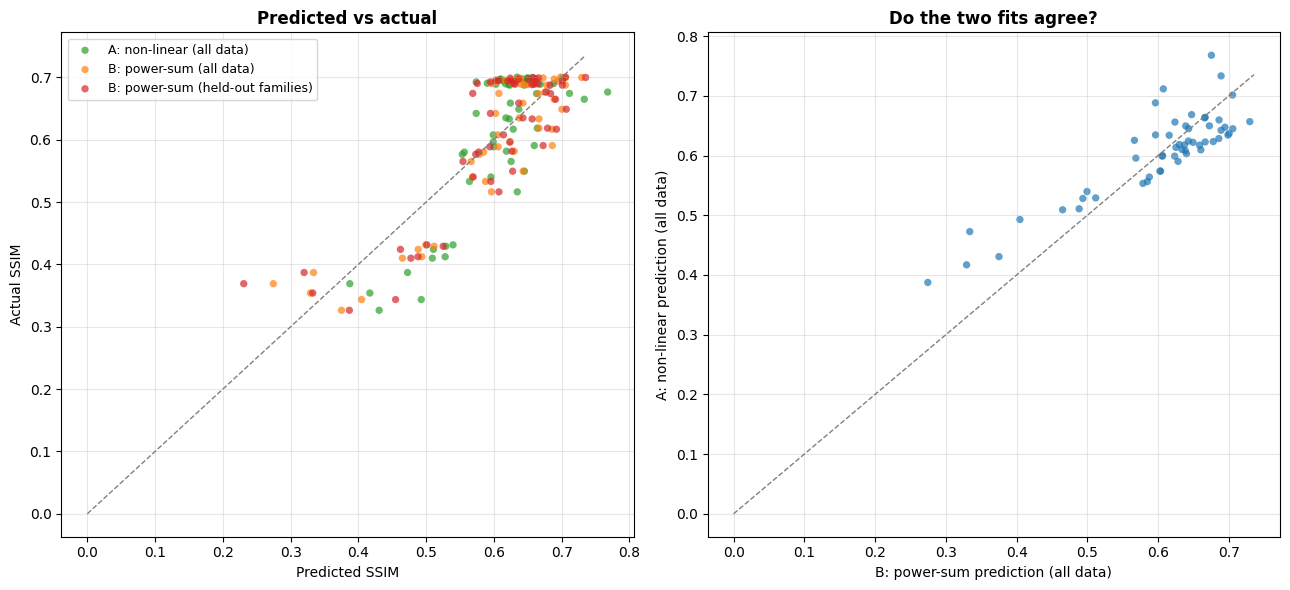

Saved /content/drive/MyDrive/Master/All data report/Comparison/ssim_prediction_comparison.png


In [ ]:
"""
Compare SSIM predictions from two non-linear fits of the same equation:

    SSIM = a*T_dir^a' + b*Diffuseness^b' + c*Opacity^c'

  Set A: the other script (curve_fit)  -> ssim_optimization_results.xlsx
  Set B: multivariate_model.py         -> multivariate_report.xlsx, sheet Pred_SSIM
         (power-sum, plus linear for reference)

Rows are matched by the 'Sample' name. Output: one Excel file with
  Metrics     R2 / RMSE / MAE / bias / max error for every prediction column
  Per-sample  actual, each prediction, residuals, and which set is closer
  Agreement   how closely Set A and Set B agree with each other
and one PNG with the comparison plots.

Note: Set A is an all-data fit (no held-out test), so compare it with the
'_all_data' columns of Set B. The '_grouped_cv' columns are shown for context
only: they are honest held-out predictions and will be worse by design.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
SET_A_FILE  = "/content/drive/MyDrive/Master/All data report/Gemini/ssim_optimization_results.xlsx"
SET_A_SHEET = 0                      # first sheet
SET_A_PRED  = "SSIM_Predicted"       # prediction column in Set A

SET_B_FILE  = "/content/drive/MyDrive/Master/All data report/Non-linear correlation/multivariate_report.xlsx"
SET_B_SHEET = "Pred_SSIM"

OUTPUT_DIR  = "/content/drive/MyDrive/Master/All data report/Comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------------
# LOAD + MERGE
# ---------------------------------------------------------------
a = pd.read_excel(SET_A_FILE, sheet_name=SET_A_SHEET)
b = pd.read_excel(SET_B_FILE, sheet_name=SET_B_SHEET)

a['Sample'] = a['Sample'].astype(str).str.strip()
b['Sample'] = b['Sample'].astype(str).str.strip()

a = a[['Sample', SET_A_PRED]].rename(columns={SET_A_PRED: 'A_NonLinear'})
m = b.merge(a, on='Sample', how='outer', indicator=True)

only_a = m.loc[m['_merge'] == 'right_only', 'Sample'].tolist()
only_b = m.loc[m['_merge'] == 'left_only', 'Sample'].tolist()
if only_a:
    print(f"WARNING: {len(only_a)} samples only in Set A (dropped): {only_a}")
if only_b:
    print(f"WARNING: {len(only_b)} samples only in Set B (dropped): {only_b}")
m = m[m['_merge'] == 'both'].drop(columns='_merge').reset_index(drop=True)
print(f"Matched {len(m)} samples")

# ---------------------------------------------------------------
# METRICS
# ---------------------------------------------------------------
LABELS = {
    'A_NonLinear':         'A: non-linear (all data)',
    'Powersum_all_data':   'B: power-sum (all data)',
    'Linear_all_data':     'B: linear (all data)',
    'Powersum_grouped_cv': 'B: power-sum (held-out families)',
    'Linear_grouped_cv':   'B: linear (held-out families)',
    'Powersum_loo_cv':     'B: power-sum (leave-one-out)',
    'Linear_loo_cv':       'B: linear (leave-one-out)',
}
cols = [c for c in LABELS if c in m.columns]
y = m['Actual'].to_numpy(float)


def scores(p):
    ok = np.isfinite(p) & np.isfinite(y)
    yy, pp = y[ok], p[ok]
    res = yy - pp
    return {
        'n': int(ok.sum()),
        'R2 (vs overall mean)': 1 - np.sum(res**2) / np.sum((yy - yy.mean())**2),
        'RMSE': np.sqrt(np.mean(res**2)),
        'MAE': np.mean(np.abs(res)),
        'Bias (mean actual - pred)': np.mean(res),
        'Max abs error': np.max(np.abs(res)),
        'Pearson r': np.corrcoef(yy, pp)[0, 1],
    }


metrics = pd.DataFrame({LABELS[c]: scores(m[c].to_numpy(float)) for c in cols}).T
metrics.index.name = 'Prediction set'
print("\n" + metrics.to_string(float_format=lambda v: f"{v:.4f}"))

# ---------------------------------------------------------------
# PER-SAMPLE TABLE
# ---------------------------------------------------------------
per = m[['Sample', 'Family', 'Actual'] + cols].copy()
for c in cols:
    per[f'Resid_{c}'] = per['Actual'] - per[c]

if 'Powersum_all_data' in m.columns:
    per['Closer_all_data'] = np.where(
        np.abs(per['Resid_A_NonLinear']) < np.abs(per['Resid_Powersum_all_data']),
        'A', 'B (power-sum)')

# ---------------------------------------------------------------
# AGREEMENT BETWEEN A AND B (same equation -> should be close)
# ---------------------------------------------------------------
agree_rows = []
for c in ['Powersum_all_data', 'Linear_all_data']:
    if c in m.columns:
        d = m['A_NonLinear'] - m[c]
        agree_rows.append({
            'Compared with': LABELS[c],
            'Pearson r (A vs B)': np.corrcoef(m['A_NonLinear'], m[c])[0, 1],
            'Mean diff (A - B)': d.mean(),
            'Max abs diff': d.abs().max(),
            'Sample with max diff': m.loc[d.abs().idxmax(), 'Sample'],
        })
agree = pd.DataFrame(agree_rows)
print("\n" + agree.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ---------------------------------------------------------------
# SAVE EXCEL
# ---------------------------------------------------------------
xlsx = os.path.join(OUTPUT_DIR, "ssim_prediction_comparison.xlsx")
with pd.ExcelWriter(xlsx, engine="openpyxl") as w:
    metrics.reset_index().to_excel(w, sheet_name="Metrics", index=False)
    per.to_excel(w, sheet_name="Per-sample", index=False)
    agree.to_excel(w, sheet_name="Agreement", index=False)
print(f"\nSaved {xlsx}")

# ---------------------------------------------------------------
# PLOTS
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
lim = (min(y.min(), 0), y.max() * 1.05)
ax[0].plot(lim, lim, '--', color='gray', lw=1)
for c, col in [('A_NonLinear', 'tab:green'), ('Powersum_all_data', 'tab:orange'),
               ('Powersum_grouped_cv', 'tab:red')]:
    if c in m.columns:
        ax[0].scatter(m[c], y, s=28, alpha=0.7, color=col, edgecolor='none', label=LABELS[c])
ax[0].set_xlabel('Predicted SSIM'); ax[0].set_ylabel('Actual SSIM')
ax[0].set_title('Predicted vs actual', fontweight='bold'); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)

if 'Powersum_all_data' in m.columns:
    ax[1].plot(lim, lim, '--', color='gray', lw=1)
    ax[1].scatter(m['Powersum_all_data'], m['A_NonLinear'], s=28, alpha=0.7, edgecolor='none')
    ax[1].set_xlabel('B: power-sum prediction (all data)')
    ax[1].set_ylabel('A: non-linear prediction (all data)')
    ax[1].set_title('Do the two fits agree?', fontweight='bold'); ax[1].grid(alpha=0.3)
plt.tight_layout()
png = os.path.join(OUTPUT_DIR, "ssim_prediction_comparison.png")
plt.savefig(png, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {png}")